# 07 · Speech: Recognition, Synthesis and Voice Cloning

This is a module of Neural Networks 1002. It assumes [module 06 of Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/06-audio-and-video-generation/) loosely (audio representations: waveforms, spectrograms, mel filter banks; we recap what we need), and [module 06 of Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/06-recurrent-networks/) (recurrent networks), [module 08](https://neural-networks.academy.forwardforecasting.eu/08-embeddings-and-seq2seq/) (classic natural language processing) and [module 09](https://neural-networks.academy.forwardforecasting.eu/09-transformer/) (the transformer).

Speech is the most natural interface between people and machines, and three families of models make it work: **automatic speech recognition** (ASR, audio in, text out), **text to speech** (TTS, text in, audio out) and **speaker models** (audio in, "who is talking" out). Combined they give speech translation and voice cloning, and the same technology that lets a person who lost their voice speak again lets a fraudster phone your grandmother. This module builds the ideas, runs the real systems on a CPU, and measures them, including how they fail.

In this notebook you will, on CPU and with fixed seeds:

1. look at the **speech pipeline**: waveform, log-mel features, acoustic model, text (and the reverse);
2. build a **CTC recogniser from scratch** (CTC, connectionist temporal classification): the loss computed by hand, a small recurrent network trained on spoken digits, **greedy** and **beam search** decoding, and the **word error rate** (WER) on speakers it has never heard;
3. run **real pre-trained recognisers**, Whisper (tiny and base) and wav2vec 2.0, and measure WER on real read speech, under added noise, across accents, and on silence, where Whisper **hallucinates**;
4. run a **real pre-trained TTS** (SpeechT5 with a HiFi-GAN vocoder), open it up stage by stage, and judge it without listening by **round-trip WER** (TTS, then ASR);
5. chain models into a **speech-to-speech translation cascade** (ASR, Marian machine translation, TTS), with language identification and translation to English by Whisper, and measure each stage;
6. measure **speaker similarity** with ECAPA-TDNN embeddings, **condition a TTS on a speaker embedding**, test how well a voice can be cloned from a short reference (using only synthetic voices), and see why zero-shot cloning with codec language models is both powerful and risky;
7. face the **ethics**: consent, voice-deepfake fraud, a measured toy **detector** that fails on an unseen generator, a toy **watermark**, and the legal frame.

**Contents**

1. The speech pipeline
2. A CTC recogniser from scratch
3. Real recognition: Whisper and wav2vec 2.0
4. Text to speech: SpeechT5 and HiFi-GAN
5. Speech-to-speech translation as a cascade
6. Speaker embeddings, similarity and voice cloning
7. Ethics, consent, fraud, detection, watermarking and law
8. Key takeaways, exercises, references

| Builds on | What we reuse |
|---|---|
| [06 Audio representations (1002)](https://neural-networks-1002.academy.forwardforecasting.eu/06-audio-and-video-generation/) | sampling rate, spectrogram, mel scale (recapped in section 1) |
| [06 Recurrent networks (1001)](https://neural-networks.academy.forwardforecasting.eu/06-recurrent-networks/) | GRU (gated recurrent unit) layers over sequences |
| [08 Classic NLP (1001)](https://neural-networks.academy.forwardforecasting.eu/08-embeddings-and-seq2seq/) | tokens, edit distance, why text needs a vocabulary |
| [09 The transformer (1001)](https://neural-networks.academy.forwardforecasting.eu/09-transformer/) | encoder-decoder attention, which Whisper and SpeechT5 are built from |

New to PyTorch? The [Python 1001 course, section on AI frameworks](https://python.academy.forwardforecasting.eu/11-ai-frameworks/) introduces it.

**Setup.** Besides the course requirements, this notebook uses `pip install transformers soundfile sentencepiece sacremoses speechbrain scipy pandas pyarrow`. Pre-trained models and the small datasets are downloaded once into `~/.cache/nn1002` and the Hugging Face cache (about 3 GB in total, no account or API key needed). Licences, stated where each is first used: Free Spoken Digit Dataset CC BY-SA 4.0; LibriSpeech CC BY 4.0; SpeechT5 MIT; Whisper, wav2vec 2.0, SpeechBrain and most Opus-MT models Apache 2.0 (as stated on their model cards; the Whisper code repository is MIT); the MMS text-to-speech models CC BY-NC 4.0 (non-commercial, fine for teaching).

**Where the toys differ from real systems.** Our from-scratch recogniser hears ten isolated-word types from six speakers (about 3000 short clips); Whisper was trained on 680 000 hours of audio and wav2vec 2.0 on 960 hours of labelled plus 53 000 hours of unlabelled speech. Our measurements on a handful of sentences are small samples: they illustrate the behaviours, they do not rank the systems. **Time and Google Colab.** The notebook is sized for a free Colab CPU runtime (about 2 virtual CPUs, 12 GB of memory, no GPU needed). Measured with 2 threads on a fast cloud CPU and the models already cached, the whole notebook executes in about 5.5 minutes. Expect roughly 10 to 15 minutes on Colab, whose cores are slower, plus a one-time download of about 3 GB of models; with an 8-core machine it is faster. The code sizes its threads from `os.cpu_count()` (override with the environment variable `NN_THREADS`).

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks-1002/07_speech_recognition_synthesis_and_voice.ipynb)

**Running in Google Colab?** Choose *Runtime > Run all*. The first code cell installs only what is missing (no session restart needed). The times shown in this notebook were measured on a multi-core machine; a free Colab CPU runtime (about 2 cores) can take several times longer.

In [ ]:
# Setup: works locally and in Google Colab. Installs only the packages that are missing.
import importlib.util, os, subprocess, sys

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'huggingface_hub': 'huggingface_hub',
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'pandas': 'pandas',
    'scipy': 'scipy',
    'sklearn': 'scikit-learn',
    'soundfile': 'soundfile',
    'speechbrain': 'speechbrain',
    'torch': 'torch',
    'torchaudio': 'torchaudio',
    'transformers': 'transformers',
    'sentencepiece': 'sentencepiece',
    'sacremoses': 'sacremoses',
    'pyarrow': 'pyarrow',
}  # import name -> pip requirement
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Installing:', ', '.join(_missing))
    _r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], capture_output=True, text=True)
    if _r.returncode:
        print('WARNING: the pip install failed; continuing. Details:\n' + _r.stderr[-400:])
print(f"Environment: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()}")

In [1]:
import os, io, re, time, math, zipfile, urllib.request, itertools, warnings
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, soundfile as sf
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from scipy.signal import resample_poly
import transformers
transformers.logging.set_verbosity_error()
from IPython.display import Audio, display

NCPU = int(os.environ.get("NN_THREADS", min(8, os.cpu_count() or 2)))      # Colab has about 2 vCPUs
torch.set_num_threads(NCPU)
torch.manual_seed(0); np.random.seed(0)
plt.rcParams["axes.grid"] = False
T_START = time.time()
CACHE = os.path.expanduser("~/.cache/nn1002"); os.makedirs(CACHE, exist_ok=True)

# ---------- helpers shared by all sections ----------
def edit_distance(ref, hyp):
    # Levenshtein distance between two sequences (lists of words or characters)
    d = list(range(len(hyp) + 1))
    for i in range(1, len(ref) + 1):
        prev, d[0] = d[:], i
        for j in range(1, len(hyp) + 1):
            d[j] = min(prev[j] + 1, d[j - 1] + 1, prev[j - 1] + (ref[i - 1] != hyp[j - 1]))
    return d[-1]

def wer(refs, hyps):
    # word error rate: (substitutions + deletions + insertions) / words in the references
    e = sum(edit_distance(r.split(), h.split()) for r, h in zip(refs, hyps))
    return e / max(1, sum(len(r.split()) for r in refs))

def cer(refs, hyps):
    e = sum(edit_distance(list(r), list(h)) for r, h in zip(refs, hyps))
    return e / max(1, sum(len(r) for r in refs))

def norm(t):
    # lower case, no punctuation: the usual normalisation before computing WER
    t = t.lower().replace("-", " ")
    return " ".join(re.sub(r"[^a-z0-9' ]", " ", t).split())

def play(a, sr=16000, label=""):
    if label: print(label)
    display(Audio(np.clip(a, -1, 1), rate=sr))

def to16k(a, sr):
    return resample_poly(a, 16000 // math.gcd(16000, sr), sr // math.gcd(16000, sr)).astype(np.float32)

print("torch", torch.__version__, "| transformers", transformers.__version__, "| threads", torch.get_num_threads())

torch 2.15.0+cpu | transformers 5.24.1 | threads 8


## 1. The speech pipeline

Sound is air pressure over time. A microphone samples it, typically 16 000 times per second (the **sampling rate**, 16 kHz), giving a long vector of numbers, the **waveform**. Raw waveforms are a poor input for a network: speech has structure at several scales (a 25 ms vowel, a 300 ms word, a 3 s sentence) and the same word looks completely different in the waveform when said by two people. So almost every speech system first computes a **log-mel spectrogram**:

1. cut the waveform into overlapping windows (25 ms long every 10 ms, called the **hop**);
2. take the magnitude of the Fourier transform in each window (how much energy at each frequency);
3. pool the frequencies with a bank of triangular filters spaced on the **mel scale** (fine resolution at low frequencies, coarse at high ones, roughly like the ear), e.g. 40 or 80 filters;
4. take the logarithm (loudness is perceived roughly logarithmically, and it turns multiplicative gain into an additive offset).

The result is an image with time on one axis and 40 to 128 "frequency bands" on the other; speech models treat it like a short, wide picture. The two big tasks are then

$$\text{ASR:}\quad \text{audio} \;\to\; \text{log-mel} \;\to\; \text{acoustic model} \;\to\; \text{text} \qquad\qquad \text{TTS:}\quad \text{text} \;\to\; \text{acoustic model} \;\to\; \text{log-mel} \;\to\; \text{vocoder} \;\to\; \text{audio}$$

where the **vocoder** is a neural network that turns a mel spectrogram back into a waveform (the spectrogram threw away the phase, which the vocoder has to invent). **Speaker models** compress a clip into a short vector (an **embedding**) that says who is talking, not what is said. We start with the data we will use for the from-scratch part.

**Data: the Free Spoken Digit Dataset** (FSDD; Jackson et al., [doi:10.5281/zenodo.1342401](https://doi.org/10.5281/zenodo.1342401), [GitHub](https://github.com/Jakobovski/free-spoken-digit-dataset), licence [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/)): 3000 recordings at 8 kHz of the digits 0 to 9, 50 per digit from each of 6 contributing speakers who released them openly, with accents recorded in the dataset's own metadata. It is small (16 MB), so we download it once and cache it. The mel filter bank below is written from scratch, in about ten lines.

3000 recordings; speakers: ['george', 'jackson', 'lucas', 'nicolas', 'theo', 'yweweler'] | mean duration 0.44 s


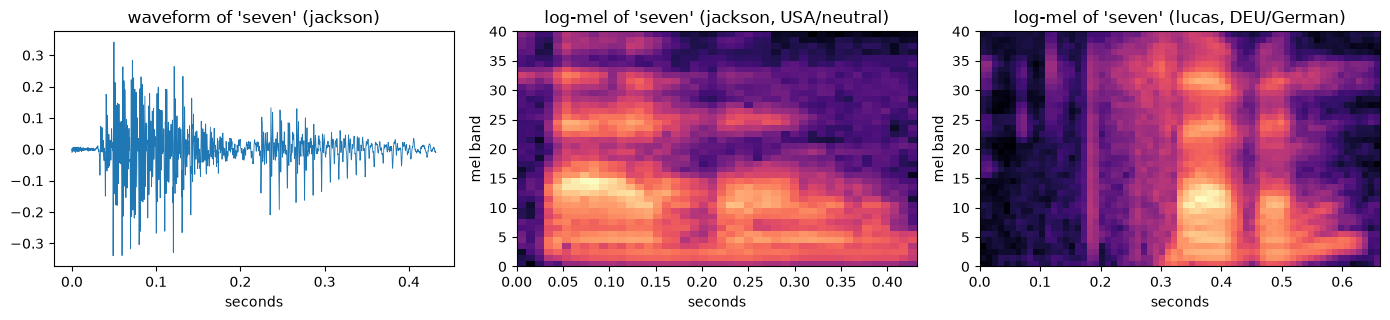

'seven' by jackson (8 kHz):


In [2]:
FSDD_ZIP = CACHE + "/fsdd.zip"
if not os.path.exists(FSDD_ZIP):
    urllib.request.urlretrieve("https://github.com/Jakobovski/free-spoken-digit-dataset/archive/refs/tags/v1.0.10.zip", FSDD_ZIP)
zf = zipfile.ZipFile(FSDD_ZIP)
WORDS = ["zero", "one", "two", "three", "four", "five", "six", "seven", "eight", "nine"]
ACCENT = {"jackson": "USA/neutral", "theo": "USA/neutral", "nicolas": "BEL/French", "george": "GRC/Greek", "yweweler": "DEU/German", "lucas": "DEU/German"}
fsdd = []
for n in zf.namelist():
    m = re.search(r"recordings/(\d)_(\w+)_(\d+)\.wav$", n)
    if m:
        a, sr = sf.read(io.BytesIO(zf.read(n)), dtype="float32"); assert sr == 8000
        fsdd.append(dict(digit=int(m.group(1)), spk=m.group(2), idx=int(m.group(3)), audio=a))
print(len(fsdd), "recordings; speakers:", sorted({c["spk"] for c in fsdd}), "| mean duration %.2f s" % np.mean([len(c["audio"]) / 8000 for c in fsdd]))

# ---- log-mel spectrogram from scratch ----
def mel_filterbank(sr, n_fft, n_mels, fmin=0.0, fmax=None):
    fmax = fmax or sr / 2
    hz2mel = lambda f: 2595 * np.log10(1 + f / 700)
    mel2hz = lambda m: 700 * (10 ** (m / 2595) - 1)
    edges = mel2hz(np.linspace(hz2mel(fmin), hz2mel(fmax), n_mels + 2))     # n_mels + 2 points on the mel axis
    freqs = np.fft.rfftfreq(n_fft, 1 / sr)
    fb = np.zeros((n_mels, len(freqs)))
    for i in range(n_mels):                                                  # one triangle per band
        lo, mid, hi = edges[i:i + 3]
        fb[i] = np.maximum(0, np.minimum((freqs - lo) / (mid - lo), (hi - freqs) / (hi - mid)))
    return torch.tensor(fb, dtype=torch.float32)

_FB = {}
def logmel(a, sr=8000, n_fft=256, hop=80, n_mels=40):
    key = (sr, n_fft, n_mels)
    if key not in _FB: _FB[key] = mel_filterbank(sr, n_fft, n_mels)
    S = torch.stft(torch.tensor(a), n_fft, hop, window=torch.hann_window(n_fft), return_complex=True).abs() ** 2
    return torch.log(_FB[key] @ S + 1e-6).T          # (frames, mel bands)

by_spk = {}
for c in fsdd: by_spk.setdefault(c["spk"], []).append(c)
seven = {s: next(c["audio"] for c in fsdd if c["digit"] == 7 and c["spk"] == s and c["idx"] == 0) for s in ["jackson", "lucas"]}
fig, ax = plt.subplots(1, 3, figsize=(14, 3.3))
ax[0].plot(np.arange(len(seven["jackson"])) / 8000, seven["jackson"], lw=0.6); ax[0].set_title("waveform of 'seven' (jackson)"); ax[0].set_xlabel("seconds")
for k, s in enumerate(["jackson", "lucas"]):
    M = logmel(seven[s]).numpy().T
    ax[k + 1].imshow(M, origin="lower", aspect="auto", cmap="magma", extent=[0, len(seven[s]) / 8000, 0, 40])
    ax[k + 1].set_title("log-mel of 'seven' (%s, %s)" % (s, ACCENT[s])); ax[k + 1].set_xlabel("seconds"); ax[k + 1].set_ylabel("mel band")
plt.tight_layout(); plt.show()
play(seven["jackson"], 8000, "'seven' by jackson (8 kHz):")

**Reading.** The same word by two speakers gives similar but not identical patterns: the two energy bursts of the fricative "s" at the start and "v" and "n" at the end, and the bands that rise and fall during the vowels, move in time and in frequency depending on the voice, the speed and the accent. An acoustic model has to learn which of that variation matters (the word) and which does not (the speaker). A second problem is **alignment**: a recording of three digits has about 200 frames but a transcript of three words, and nobody tells us which frame belongs to which letter. Section 2 shows the trick that solved this for a decade of speech recognition.

## 2. A CTC recogniser from scratch

### 2.1 The alignment problem and the CTC loss

We want a network that reads $T$ frames of log-mel features and writes a transcript of $L$ characters, with $L$ usually much smaller than $T$ and no frame-level labels. **Connectionist temporal classification** (CTC; Graves et al., 2006, [paper](https://www.cs.toronto.edu/~graves/icml_2006.pdf)) does it with two ideas.

1. The network outputs, at **every** frame $t$, a probability distribution over the characters plus one special symbol, the **blank** ($\varnothing$, "nothing new here"). Call the probability of symbol $k$ at frame $t$ $y_t(k)$.
2. A frame-by-frame sequence $\pi = (\pi_1, \dots, \pi_T)$ (a **path**) is turned into text by the collapse map $\mathcal{B}$: first merge repeated symbols, then delete blanks. So `hh∅e∅ll∅ll∅o` becomes `hello`, and the blank between the two `ll` is what lets a real double letter survive.

The probability of a transcript $\ell$ is the sum over **all paths that collapse to it**, assuming the frames are independent given the audio:

$$P(\ell \mid x) = \sum_{\pi:\,\mathcal{B}(\pi) = \ell}\; \prod_{t=1}^{T} y_t(\pi_t), \qquad \mathcal{L}_\text{CTC} = -\ln P(\ell \mid x).$$

There are exponentially many paths, but a **dynamic program** (the forward algorithm) sums them in $O(T \cdot L)$ time: write the target with blanks around every symbol, $\ell' = \varnothing\, \ell_1 \varnothing\, \ell_2 \dots \ell_L \varnothing$, and let $\alpha_t(s)$ be the probability of all path prefixes of length $t$ that end in position $s$ of $\ell'$. Then $\alpha_t(s) = \big(\alpha_{t-1}(s) + \alpha_{t-1}(s-1) + [\,\ell'_s \ne \varnothing,\ \ell'_s \ne \ell'_{s-2}\,]\;\alpha_{t-1}(s-2)\big)\, y_t(\ell'_s)$ and $P(\ell \mid x) = \alpha_T(|\ell'|) + \alpha_T(|\ell'| - 1)$. Because it is a differentiable sum, gradients flow to the network and the alignment is **marginalised out**, never chosen. Let us check it on a case small enough to enumerate: 4 frames, symbols $\{\varnothing, a, b\}$, target "ab".

In [3]:
torch.manual_seed(0)
T_toy, V_toy = 4, 3                                  # 4 frames, symbols: 0 = blank, 1 = 'a', 2 = 'b'
lp = torch.randn(T_toy, V_toy).log_softmax(-1)       # per-frame log-probabilities from a pretend network

def collapse(path):                                  # the map B: merge repeats, then drop blanks
    out, prev = [], None
    for s in path:
        if s != prev and s != 0: out.append(s)
        prev = s
    return tuple(out)

def collapse_str(s):
    return "".join(ch for i, ch in enumerate(s) if ch != "_" and (i == 0 or ch != s[i - 1]))
print("collapse('hh_e_ll_ll_o') ->", collapse_str("hh_e_ll_ll_o"), "| collapse('hhheeellloo') ->", collapse_str("hhheeellloo"))

# 1) brute force: enumerate all 3^4 = 81 paths and add up those that collapse to "ab" = (1, 2)
good = [p for p in itertools.product(range(V_toy), repeat=T_toy) if collapse(p) == (1, 2)]
p_brute = sum(math.exp(sum(lp[t, s].item() for t, s in enumerate(p))) for p in good)
print("paths that collapse to 'ab':", len(good), "of", V_toy ** T_toy, "->", good)

# 2) the forward dynamic program on the blank-extended target  [_, a, _, b, _]
def ctc_forward(lp, target):
    ext = [0]
    for s in target: ext += [s, 0]
    T, S = lp.shape[0], len(ext)
    alpha = np.zeros((T, S)); alpha[0, 0] = lp[0, 0].exp().item(); alpha[0, 1] = lp[0, ext[1]].exp().item()
    for t in range(1, T):
        for s in range(S):
            a = alpha[t - 1, s] + (alpha[t - 1, s - 1] if s >= 1 else 0)
            if s >= 2 and ext[s] != 0 and ext[s] != ext[s - 2]: a += alpha[t - 1, s - 2]
            alpha[t, s] = a * lp[t, ext[s]].exp().item()
    return alpha[-1, -1] + alpha[-1, -2], alpha
p_dp, alpha = ctc_forward(lp, [1, 2])

# 3) PyTorch's implementation
loss_torch = F.ctc_loss(lp[:, None, :], torch.tensor([[1, 2]]), torch.tensor([T_toy]), torch.tensor([2]), blank=0, reduction="sum")
print("-ln P  brute force: %.6f | forward algorithm: %.6f | F.ctc_loss: %.6f" % (-math.log(p_brute), -math.log(p_dp), loss_torch.item()))

collapse('hh_e_ll_ll_o') -> hello | collapse('hhheeellloo') -> helo
paths that collapse to 'ab': 15 of 81 -> [(0, 0, 1, 2), (0, 1, 0, 2), (0, 1, 1, 2), (0, 1, 2, 0), (0, 1, 2, 2), (1, 0, 0, 2), (1, 0, 2, 0), (1, 0, 2, 2), (1, 1, 0, 2), (1, 1, 1, 2), (1, 1, 2, 0), (1, 1, 2, 2), (1, 2, 0, 0), (1, 2, 2, 0), (1, 2, 2, 2)]
-ln P  brute force: 1.299563 | forward algorithm: 1.299563 | F.ctc_loss: 1.299563


**Reading.** The three numbers agree to six digits: enumerating the paths, the $O(T \cdot L)$ recursion and PyTorch's `ctc_loss` compute the same thing. Of the 81 possible 4-frame paths only 15 collapse to "ab" (for example `a b ∅ ∅`, `∅ a a b`, `a ∅ b b`), and the loss is minus the log of their total probability. Training pushes probability mass onto *some* of those paths without ever choosing which; in practice networks converge to **peaky** outputs: one frame emits the character and the others emit blank, as we will see in the posterior plot. CTC assumes the frames are conditionally independent, so it has no built-in language model; that matters in section 2.4.

### 2.2 Data: sequences of spoken digits, with speakers held out

Isolated digits would not need CTC, so we build **sequences** of 3 to 5 digits by splicing recordings together with short silent gaps (we splice the features rather than the waveforms, which is faster and almost equivalent). The transcript is the spelled-out words, `"seven two nine"`, so the output symbols are the 15 letters that occur in the digit names, the space and the blank (17 in total): a **character-level** model, as in real recognisers. Splits:

* **train**: 5 speakers, recordings numbered 5 to 49 (the dataset's own convention puts 0 to 4 in the test set);
* **seen speakers, new recordings**: the same 5 speakers, recordings 0 to 4;
* **unseen speaker**: *lucas* (German accent), never used in training, every recording.

In [4]:
feats = [dict(c, f=logmel(c["audio"])) for c in fsdd]                       # (frames, 40) per clip
allf = torch.cat([c["f"] for c in feats]); MU, SD = allf.mean(0), allf.std(0)
NM = 40
SIL = torch.full((1, NM), math.log(1e-6))                                    # a "silent" frame
VOCAB = ["_"] + sorted(set("".join(WORDS))) + [" "]                          # "_" is the CTC blank
c2i = {c: i for i, c in enumerate(VOCAB)}
TRAIN_SPK, HELD = ["jackson", "theo", "nicolas", "george", "yweweler"], "lucas"
pool = {}
for c in feats: pool.setdefault((c["spk"], c["idx"] < 5), []).append((c["digit"], c["f"]))

def make_sequence(rng, spks, test, noise=0.0):
    k = rng.integers(3, 6); digits, parts = [], []
    for _ in range(k):
        cand = pool[(spks[rng.integers(len(spks))], test)]
        d, f = cand[rng.integers(len(cand))]
        parts += [SIL.expand(rng.integers(3, 20), NM), f]; digits.append(d)
    parts.append(SIL.expand(rng.integers(3, 20), NM))
    X = (torch.cat(parts) - MU) / SD
    return (X + noise * torch.randn_like(X) if noise else X), digits

def spell(digits): return " ".join(WORDS[d] for d in digits)

def batchify(items):
    T = max(len(x) for x, _ in items)
    X = torch.zeros(len(items), T, NM); lens = torch.tensor([len(x) for x, _ in items])
    for i, (x, _) in enumerate(items): X[i, :len(x)] = x
    tg = [torch.tensor([c2i[c] for c in spell(d)]) for _, d in items]
    return X, lens, torch.cat(tg), torch.tensor([len(t) for t in tg])

rng0 = np.random.default_rng(0)
x, d = make_sequence(rng0, TRAIN_SPK, False)
print("one training example: digits", d, "->", repr(spell(d)), "| frames:", len(x), "| target characters:", len(spell(d)))
print("vocabulary (%d symbols):" % len(VOCAB), "".join(VOCAB))

one training example: digits [5, 0, 1, 9, 9] -> 'five zero one nine nine' | frames: 331 | target characters: 23
vocabulary (17 symbols): _efghinorstuvwxz 


### 2.3 The model and its training

Two strided 1-D convolutions (each halves the number of frames, so the network works at 25 frames per second, plenty for 29 output characters over about 4 s) feed a 2-layer **bidirectional** GRU (it reads the sequence forwards and backwards, so each frame sees its context on both sides), and a linear layer produces the 17 log-probabilities per frame. We train with the CTC loss, AdamW and a one-cycle learning-rate schedule, adding Gaussian noise to the features as a cheap augmentation.

parameters: 606737


step    0  CTC loss 5.398


step  100  CTC loss 1.602


step  200  CTC loss 0.087


step  300  CTC loss 0.013


step  400  CTC loss 0.008


training took 61 s


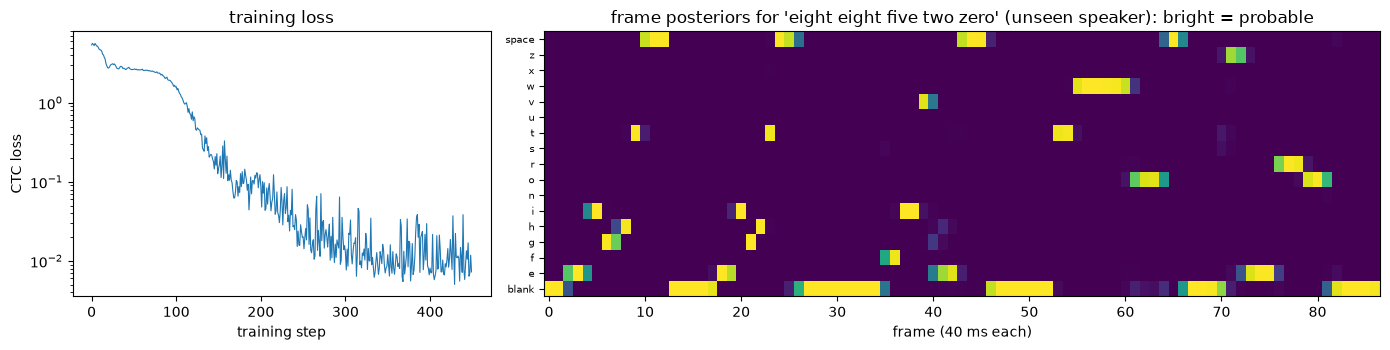

In [5]:
class CTCNet(nn.Module):
    def __init__(s, h=128):
        super().__init__()
        s.conv = nn.Sequential(nn.Conv1d(NM, h, 5, 2, 2), nn.GELU(), nn.Conv1d(h, h, 5, 2, 2), nn.GELU())   # 4x fewer frames
        s.rnn = nn.GRU(h, h, 2, batch_first=True, bidirectional=True, dropout=0.1)
        s.out = nn.Linear(2 * h, len(VOCAB))
    def forward(s, X, lens):
        z = s.conv(X.transpose(1, 2)).transpose(1, 2)
        return s.out(s.rnn(z)[0]).log_softmax(-1), (lens + 3) // 4          # log-probs (batch, T/4, 17) and their lengths

torch.manual_seed(0); rng = np.random.default_rng(0)
net = CTCNet(); print("parameters:", sum(p.numel() for p in net.parameters()))
STEPS = 450
opt = torch.optim.AdamW(net.parameters(), 2e-3, weight_decay=1e-2)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, 3e-3, total_steps=STEPS)
t0 = time.time(); losses = []
for step in range(STEPS):
    X, L, tg, tl = batchify([make_sequence(rng, TRAIN_SPK, False, noise=0.1) for _ in range(32)])
    lp_b, ol = net(X, L)
    loss = F.ctc_loss(lp_b.transpose(0, 1), tg, ol, tl, blank=0, zero_infinity=True)
    opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(net.parameters(), 5.0); opt.step(); sched.step()
    losses.append(loss.item())
    if step % 100 == 0: print("step %4d  CTC loss %.3f" % (step, loss.item()))
print("training took %.0f s" % (time.time() - t0))
net.eval()

# posteriors for one utterance of the unseen speaker
r = np.random.default_rng(5); xs, ds = make_sequence(r, [HELD], False)
with torch.no_grad(): lp_u, ol_u = net(xs[None], torch.tensor([len(xs)]))
P = lp_u[0].exp().numpy()
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6), gridspec_kw={"width_ratios": [1, 2]})
ax[0].semilogy(losses, lw=0.8); ax[0].set_xlabel("training step"); ax[0].set_ylabel("CTC loss"); ax[0].set_title("training loss")
ax[1].imshow(P.T, origin="lower", aspect="auto", cmap="viridis")
ax[1].set_yticks(range(len(VOCAB))); ax[1].set_yticklabels(["blank" if c == "_" else ("space" if c == " " else c) for c in VOCAB], fontsize=7)
ax[1].set_xlabel("frame (40 ms each)"); ax[1].set_title("frame posteriors for '%s' (unseen speaker): bright = probable" % spell(ds))
plt.tight_layout(); plt.show()

**Reading.** The loss falls from about 5 to nearly zero within a few hundred steps. The posterior plot shows the signature CTC behaviour: the blank row is bright almost everywhere, and every character appears as a short, sharp vertical streak at the frame where the network decided it was complete, usually *after* part of the sound has passed. The network never saw an alignment, yet it learned a consistent one. Next, how to read the transcript out of those posteriors.

### 2.4 Decoding: greedy, beam search and a word lexicon

* **Greedy decoding**: take the most probable symbol at each frame, then apply the collapse map $\mathcal{B}$. Fast, but it commits early and ignores that many paths collapse to the same text.
* **Prefix beam search** (Hannun, 2014, [arXiv 1408.2873](https://arxiv.org/abs/1408.2873)): keep the $B$ best *text prefixes* (not paths) and, for each, the total probability of all paths that collapse to it, split into "ends in blank" and "ends in a character" so that repeated letters are handled correctly. This sums over alignments, which is exactly what the loss does.
* **Shallow fusion with a lexicon**: CTC has no language knowledge, but we know every word is a digit name. At each word boundary we add a bonus $\beta$ to the score of a prefix whose last word is a valid digit name and subtract it otherwise. Real systems do the same with an $n$-gram or neural language model.

In [6]:
def greedy_decode(lp_t):
    ids, out, prev = lp_t.argmax(-1).tolist(), [], None
    for i in ids:
        if i != prev and i != 0: out.append(VOCAB[i])
        prev = i
    return "".join(out)

NEG = -1e30
def lse(a, b):
    if a < b: a, b = b, a
    return a if b <= NEG else a + math.log1p(math.exp(b - a))

def beam_decode(lp_np, beam=8, lexicon=None, beta=0.0, prune=-7.0):
    # prefix beam search. beams: prefix -> [log P(ends in blank), log P(ends in a character)]
    def bonus(prefix):                                       # score the last (finished) word of a prefix
        if lexicon is None: return 0.0
        w = prefix.rstrip().split(" ")[-1]
        return beta if w in lexicon else -beta
    beams = {"": [0.0, NEG]}
    for t in range(lp_np.shape[0]):
        nxt = {}
        def add(prefix, which, v):
            e = nxt.setdefault(prefix, [NEG, NEG]); e[which] = lse(e[which], v)
        for prefix, (pb, pnb) in beams.items():
            tot = lse(pb, pnb)
            for k in np.where(lp_np[t] > prune)[0]:
                p = lp_np[t, k]
                if k == 0: add(prefix, 0, tot + p); continue
                c = VOCAB[k]
                if prefix and prefix[-1] == c:
                    add(prefix, 1, pnb + p)                  # repeat without a blank in between: same prefix
                    new = prefix + c; add(new, 1, pb + p)    # repeat after a blank: a real double letter
                else:
                    if c == " " and (prefix == "" or prefix[-1] == " "): continue
                    new = prefix + c
                    add(new, 1, tot + p + (bonus(prefix) if c == " " else 0.0))
        beams = dict(sorted(nxt.items(), key=lambda kv: -lse(*kv[1]))[:beam])
    best = max(beams.items(), key=lambda kv: lse(*kv[1]) + bonus(kv[0]))
    return best[0].strip()

LEX = set(WORDS)

def evaluate(spks, test, n=120, seed=1, noise=0.0):
    r = np.random.default_rng(seed); items = [make_sequence(r, spks, test, noise) for _ in range(n)]
    X, L, _, _ = batchify(items)
    with torch.no_grad(): lpb, ol = net(X, L)
    refs = [spell(d) for _, d in items]
    out = {"greedy": [], "beam 8": [], "beam 8 + lexicon": []}
    for k in range(n):
        l = lpb[k, :ol[k]]
        out["greedy"].append(greedy_decode(l))
        out["beam 8"].append(beam_decode(l.numpy(), 8))
        out["beam 8 + lexicon"].append(beam_decode(l.numpy(), 8, LEX, 2.0))
    return refs, out

sets = {"seen speakers, new recordings": dict(spks=TRAIN_SPK, test=True),
        "seen speakers, noisy features": dict(spks=TRAIN_SPK, test=True, noise=0.7),
        "unseen speaker (lucas, German accent)": dict(spks=[HELD], test=False)}
rows, store = [], {}
t0 = time.time()
for name, kw in sets.items():
    refs, out = evaluate(**kw); store[name] = (refs, out)
    for dec, hyp in out.items():
        rows.append(dict(test_set=name, decoder=dec, WER=round(wer(refs, hyp), 3), CER=round(cer(refs, hyp), 3)))
res = pd.DataFrame(rows); display(res.pivot(index="test_set", columns="decoder", values="WER")[["greedy", "beam 8", "beam 8 + lexicon"]])
print("decoding took %.0f s" % (time.time() - t0))
refs, out = store["unseen speaker (lucas, German accent)"]
bad = [i for i in range(len(refs)) if out["greedy"][i] != refs[i]][:4]
for i in bad:
    print("ref    :", refs[i]); print("greedy :", out["greedy"][i]); print("beam   :", out["beam 8"][i]); print("+lexicon:", out["beam 8 + lexicon"][i]); print()

decoder,greedy,beam 8,beam 8 + lexicon
test_set,,,
"seen speakers, new recordings",0.011,0.011,0.008
"seen speakers, noisy features",0.032,0.030,0.019
"unseen speaker (lucas, German accent)",0.299,0.287,0.193


decoding took 2 s
ref    : five nine one nine
greedy : five nie one nine
beam   : five nine one nine
+lexicon: five nine one nine

ref    : four eight four five zero
greedy : four eight one five zeroe
beam   : four eight one five zeroe
+lexicon: four eight one five zero

ref    : five three seven three four
greedy : five three thrvee three one
beam   : five three thrvee three one
+lexicon: five three three three one

ref    : four two two seven
greedy : four twro two seven
beam   : four twro two seven
+lexicon: four two two seven



**Reading.** On new recordings of speakers it has heard, the model is almost perfect (word error rate 1.1 % with greedy decoding), and it reads 3.2 % wrong when we add noise to the features. On the **unseen speaker** it makes 29.9 % word errors with greedy decoding: with only five training voices, one more voice (a German accent) is already out of distribution, which is the main lesson of this section and the reason real systems are trained on thousands of speakers. Beam search alone barely helps (28.7 %), because the mistakes are in the acoustic evidence (the network is wrong about a frame, and every alignment of a wrong frame is wrong), not in the search. The **lexicon** helps more (19.3 %): it repairs malformed words such as `twro` or `zeroe` into `two` and `zero`, but it cannot repair a valid wrong word (`one` for `four`), and it can turn a malformed word into the wrong valid one (`thrvee` became `three` where the speaker said `seven`). Caveats: 120 sequences (about 480 words) per set and a single training seed, so differences of a point or two are noise; the 1.1 % on seen speakers is optimistic because the test recordings come from the same sessions as the training ones.

**Where the toy differs from real systems.** Real recognisers have thousands of hours of transcribed audio, tens of thousands of hours of speakers, microphones and rooms, and output sub-word units instead of letters, so a new voice is almost never as foreign as *lucas* is to a five-speaker model. They also use far larger networks (Conformer, a convolution-augmented transformer, instead of a GRU) and either a language model during decoding or a decoder network that writes the text word by word, as Whisper does next.

## 3. Real recognition: Whisper and wav2vec 2.0

Two pre-trained models, both used through the `transformers` library:

* **wav2vec 2.0** (Baevski et al., 2020, [arXiv 2006.11477](https://arxiv.org/abs/2006.11477)) is a transformer encoder over the waveform, first pre-trained *without labels* (it learns to identify masked audio from context) and then fine-tuned with a **CTC** head, exactly the loss of section 2. We use `facebook/wav2vec2-base-960h` (95 M parameters, fine-tuned on 960 h of LibriSpeech, Apache 2.0 licence, [model card](https://huggingface.co/facebook/wav2vec2-base-960h)).
* **Whisper** (Radford et al., 2022, [arXiv 2212.04356](https://arxiv.org/abs/2212.04356)) is an **encoder-decoder transformer** trained on 680 000 hours of audio with transcripts scraped from the web, in about 100 languages. Instead of CTC, the decoder writes the text token by token and is steered by special tokens: language, task (transcribe or translate to English), timestamps. We use `openai/whisper-tiny` (39 M parameters) and `openai/whisper-base` (74 M), and `whisper-small` (244 M) later; Apache 2.0 licence on the model cards (the code repository is MIT), [model card](https://huggingface.co/openai/whisper-base). Whisper pads or trims every input to 30 s.

**Test data**: the `clean/validation` split of LibriSpeech (Panayotov et al., 2015, [doi:10.1109/ICASSP.2015.7178964](https://doi.org/10.1109/ICASSP.2015.7178964), CC BY 4.0) in the small dummy copy [`hf-internal-testing/librispeech_asr_dummy`](https://huggingface.co/datasets/hf-internal-testing/librispeech_asr_dummy): 73 read audiobook sentences from a public-domain recording by one volunteer reader (so it cannot test speaker variety). We take 12 clips of at most 15 s. Since the references are the book text, **WER is exact**, but this is the *easiest* kind of speech (read, clean, one speaker, good microphone).

In [7]:
from huggingface_hub import hf_hub_download
from transformers import (WhisperProcessor, WhisperForConditionalGeneration, Wav2Vec2Processor, Wav2Vec2ForCTC)
p = hf_hub_download("hf-internal-testing/librispeech_asr_dummy", "clean/validation-00000-of-00001.parquet", repo_type="dataset")
df = pd.read_parquet(p)
ls_all = []
for r_ in df.itertuples():
    a, sr = sf.read(io.BytesIO(r_.audio["bytes"]), dtype="float32"); assert sr == 16000
    ls_all.append(dict(audio=a, text=norm(r_.text), spk=r_.speaker_id, dur=len(a) / sr))
print(len(ls_all), "LibriSpeech clips from", len({c["spk"] for c in ls_all}), "speakers")
LS = [c for c in ls_all if 3 <= c["dur"] <= 15][:8]
print("test clips:", len(LS), "| total %.0f s" % sum(c["dur"] for c in LS), "| words:", sum(len(c["text"].split()) for c in LS))
print("example reference:", LS[0]["text"])

_W = {}
def whisper(name):
    if name not in _W:
        _W[name] = (WhisperProcessor.from_pretrained(name), WhisperForConditionalGeneration.from_pretrained(name).eval())
    return _W[name]

@torch.no_grad()
def asr_whisper(name, audios, language="en", task="transcribe", bs=6):
    proc, m = whisper(name); out = []
    for i in range(0, len(audios), bs):
        f = proc(audios[i:i + bs], sampling_rate=16000, return_tensors="pt").input_features
        kw = dict(task=task, max_new_tokens=220)
        if language: kw["language"] = language
        out += proc.batch_decode(m.generate(f, **kw), skip_special_tokens=True)
    return [o.strip() for o in out]

W2V = (Wav2Vec2Processor.from_pretrained("facebook/wav2vec2-base-960h"), Wav2Vec2ForCTC.from_pretrained("facebook/wav2vec2-base-960h").eval())
@torch.no_grad()
def asr_w2v(audios, return_logits=False):
    proc, m = W2V; out = []
    for a in audios:
        lg = m(proc(a, sampling_rate=16000, return_tensors="pt").input_values).logits
        out.append(lg if return_logits else proc.batch_decode(lg.argmax(-1))[0].lower())
    return out

SYSTEMS = {"whisper-tiny": lambda au: asr_whisper("openai/whisper-tiny", au),
           "whisper-base": lambda au: asr_whisper("openai/whisper-base", au),
           "wav2vec2-base-960h (CTC)": asr_w2v}
t0 = time.time(); refs_ls = [c["text"] for c in LS]; clean_hyp = {}
for name, fn in SYSTEMS.items():
    t1 = time.time(); clean_hyp[name] = [norm(h) for h in fn([c["audio"] for c in LS])]
    print("%-26s WER %.3f   CER %.3f   (%.1f s for %.0f s of audio)" % (name, wer(refs_ls, clean_hyp[name]), cer(refs_ls, clean_hyp[name]), time.time() - t1, sum(c["dur"] for c in LS)))
worst = max(range(len(LS)), key=lambda i: edit_distance(refs_ls[i].split(), clean_hyp["whisper-tiny"][i].split()))
print("\nclip with most whisper-tiny errors:\n ref :", refs_ls[worst], "\n tiny:", clean_hyp["whisper-tiny"][worst], "\n base:", clean_hyp["whisper-base"][worst], "\n w2v :", clean_hyp["wav2vec2-base-960h (CTC)"][worst])

73 LibriSpeech clips from 1 speakers
test clips: 8 | total 62 s | words: 143
example reference: mister quilter is the apostle of the middle classes and we are glad to welcome his gospel


whisper-tiny               WER 0.077   CER 0.042   (2.0 s for 62 s of audio)


whisper-base               WER 0.077   CER 0.040   (3.2 s for 62 s of audio)


wav2vec2-base-960h (CTC)   WER 0.035   CER 0.013   (2.0 s for 62 s of audio)

clip with most whisper-tiny errors:
 ref : nor is mister quilter's manner less interesting than his matter 
 tiny: nor is mr quilters' manner less interesting than his matter 
 base: nor is mr quilter's manner less interesting than his matter 
 w2v : nor is mister quilter's manner less interesting than his matter


**Reading.** On 8 read sentences (143 words) the CTC-trained wav2vec 2.0 has the lowest WER (3.5 %), against 7.7 % for both Whisper-base and Whisper-tiny. One word is 0.7 percentage points here, so the two Whisper models cannot be told apart, but the gap to wav2vec 2.0 is real on this sample and has a simple explanation: wav2vec 2.0 was fine-tuned on LibriSpeech, the same kind of audio and text, while Whisper is evaluated **zero-shot** and writes some words as a writer would (`mr` for `mister`; the reference spells titles out, so this counts as an error although the speech was understood, a reminder that WER depends on text normalisation). In-domain accuracy is not robustness, as the next experiments show. Speed on 2 CPU threads: 62 s of audio in 2.0 s (tiny), 3.3 s (base) and 2.1 s (wav2vec 2.0), far faster than real time.

### 3.1 What a real CTC model looks like

wav2vec 2.0 is trained with the very loss we computed by hand, so its frame outputs should look like our posteriors: mostly blank, with a character at the moment it is complete. Frames are 20 ms apart; the vocabulary's blank is the padding token and `|` marks a word boundary. Here are the argmax symbols of 70 consecutive frames of the first clip.

In [8]:
lg = asr_w2v([LS[0]["audio"]], return_logits=True)[0]
toks = W2V[0].tokenizer.convert_ids_to_tokens(lg.argmax(-1)[0].tolist())
frames = ["_" if t == "<pad>" else t for t in toks]
print("".join(frames[30:100]))
print("collapsed (repeats merged, blanks dropped):", W2V[0].batch_decode(lg.argmax(-1))[0].lower()[:60])
print("fraction of frames that are blank: %.2f" % np.mean([t == "_" for t in frames]))

_ISS_T_E_R||_Q_U__ILL__T___ERR_|||__ISS|||THEE||__A___P_____OSS__TT_LL
collapsed (repeats merged, blanks dropped): mister quilter is the apostle of the middle classes and we a
fraction of frames that are blank: 0.51


**Reading.** The frame string shows CTC on a real model: about half of the frames (51 %) are blank, the letters are spread over one to three frames (`LL`, `TT`, `OSS`) rather than perfectly single-frame spikes, and word boundaries `|` appear between them. `_ISS_T_E_R` collapses to `mister` only after the merge and delete steps of section 2.1, exactly the rule we computed by hand.

### 3.2 Behaviour under noise

We add white Gaussian noise to the clean clips at a given **signal-to-noise ratio** (SNR, in decibels: 20 dB means the noise has 1 % of the signal power, 0 dB equal power, minus 5 dB more noise than signal) and a "babble" condition where a second voice (a string of spoken digits from the FSDD speakers) talks over the first at 5 dB. Real noise (traffic, a kitchen, a crowded room) is neither white nor stationary, so these are optimistic.

,clean,white 10 dB,white 0 dB,white -5 dB,babble 5 dB
whisper-tiny,0.077,0.217,0.678,1.755,0.371
whisper-base,0.077,0.168,0.455,2.056,0.217
wav2vec2-base-960h (CTC),0.035,0.175,0.972,1.000,0.727


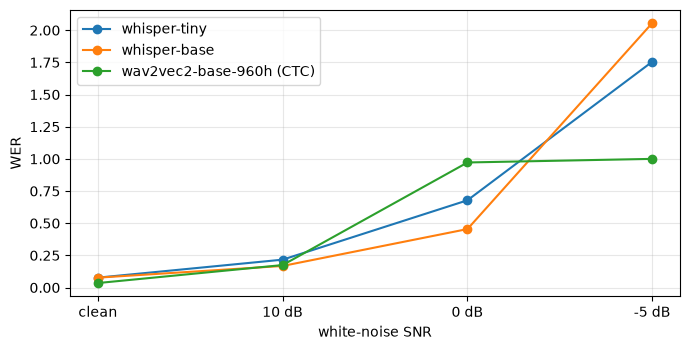

noise experiment took 35 s


In [9]:
def add_white(a, snr_db, seed):
    n = np.random.default_rng(seed).standard_normal(len(a)).astype(np.float32)
    return a + n * np.sqrt((a ** 2).mean() / 10 ** (snr_db / 10)) / n.std()

def add_babble(a, other, snr_db):
    o = np.resize(other, len(a)); return a + o * np.sqrt((a ** 2).mean() / 10 ** (snr_db / 10)) / np.sqrt((o ** 2).mean())

# the LibriSpeech dummy copy has a single reader, so the competing talkers are FSDD digit strings from other speakers
rb = np.random.default_rng(11)
others = [to16k(np.concatenate([c["audio"] for c in [by_spk[s_][j] for j in rb.integers(len(by_spk[s_]), size=12)]]), 8000) for s_ in ["lucas", "george", "nicolas", "jackson"]]
conds = {"clean": lambda a, i: a,
         "white 10 dB": lambda a, i: add_white(a, 10, i),
         "white 0 dB": lambda a, i: add_white(a, 0, i), "white -5 dB": lambda a, i: add_white(a, -5, i),
         "babble 5 dB": lambda a, i: add_babble(a, others[i % len(others)], 5)}
t0 = time.time(); noise_res = {s: {} for s in SYSTEMS}
for cname, fn_c in conds.items():
    noisy = [fn_c(c["audio"], i) for i, c in enumerate(LS)]
    for s, fn in SYSTEMS.items():
        noise_res[s][cname] = wer(refs_ls, [norm(h) for h in fn(noisy)])
nr = pd.DataFrame(noise_res).T[list(conds)]; display(nr.round(3))
fig, ax = plt.subplots(figsize=(7, 3.6))
for s in SYSTEMS: ax.plot(range(4), [noise_res[s][c] for c in list(conds)[:4]], "o-", label=s)
ax.set_xticks(range(4)); ax.set_xticklabels(["clean", "10 dB", "0 dB", "-5 dB"]); ax.set_xlabel("white-noise SNR"); ax.set_ylabel("WER"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show(); print("noise experiment took %.0f s" % (time.time() - t0))

**Reading.** At 10 dB of white noise the three systems behave alike (WER 16.8 % to 21.7 %). At 0 dB, where signal and noise have equal power, the picture changes: Whisper-base keeps 46 % WER and Whisper-tiny 68 %, but wav2vec 2.0, the best system on clean speech, reaches 97 %: a recogniser fine-tuned on clean audio breaks abruptly outside its conditions, while one trained on 680 000 hours of varied audio degrades gradually. At minus 5 dB nothing works, and the WER of the Whisper models exceeds 100 % (1.76 for tiny and 2.06 for base) because the decoder **invents** words and loops: a WER above 1 means more insertions than there were words to recognise. A second talker at 5 dB hurts the CTC model most (73 % against 22 % for Whisper-base), since it has no mechanism for deciding which voice to follow. Caveats: white noise is the easiest kind to model, 8 clips and one noise draw per condition.

### 3.3 Accents: the digit speakers

FSDD records the accent of each speaker, which lets us run a small, honest check of how a general-purpose recogniser treats different accents. For each speaker we build 8 sequences of 4 random digits (200 ms of silence between them, resampled from 8 kHz to 16 kHz) and transcribe them with Whisper. Whisper writes digits as numerals or as words, so we normalise both to words and map the usual homophones (to/too to two, for to four, won to one, ate to eight, oh to zero) the same way for everybody. **This is 8 sequences (32 digits) per speaker, one person per accent**: it shows a pattern, it does not measure "the German accent".

In [10]:
HOMO = {"to": "two", "too": "two", "for": "four", "won": "one", "ate": "eight", "oh": "zero", "o": "zero"}
def norm_digits(t):
    t = re.sub(r"\d", lambda m: " %s " % WORDS[int(m.group())], t.lower())
    return " ".join(HOMO.get(w, w) for w in norm(t).split())

rng_a = np.random.default_rng(3)
acc_audio, acc_ref, acc_spk = [], [], []
for s, cl in sorted(by_spk.items()):
    for _ in range(8):
        pick = [cl[i] for i in rng_a.integers(len(cl), size=4)]
        wav = np.concatenate([np.concatenate([np.zeros(1600, np.float32), c["audio"]]) for c in pick] + [np.zeros(1600, np.float32)])
        acc_audio.append(to16k(wav, 8000)); acc_ref.append(spell([c["digit"] for c in pick])); acc_spk.append(s)
rows = []
for name in ["openai/whisper-tiny", "openai/whisper-base"]:
    hyp = [norm_digits(h) for h in asr_whisper(name, acc_audio)]
    for s in sorted(by_spk):
        idx = [i for i, x in enumerate(acc_spk) if x == s]
        rows.append(dict(model=name.split("/")[1], speaker=s, accent=ACCENT[s], WER=round(wer([acc_ref[i] for i in idx], [hyp[i] for i in idx]), 3)))
acc = pd.DataFrame(rows); display(acc.pivot(index=["speaker", "accent"], columns="model", values="WER"))
i0 = acc_spk.index("nicolas"); print("example (nicolas): ref", acc_ref[i0], "| whisper-base heard:", hyp[i0])

,model,whisper-base,whisper-tiny
speaker,accent,,
george,GRC/Greek,0.062,0.062
jackson,USA/neutral,0.000,0.000
lucas,DEU/German,0.000,0.031
nicolas,BEL/French,0.344,0.469
theo,USA/neutral,0.031,0.031
yweweler,DEU/German,0.000,0.125


example (nicolas): ref five eight six three | whisper-base heard: five eight six two one


**Reading.** Whisper-base transcribes five of the six speakers with 0 % to 6 % word errors, including both German-accent speakers (0.0 % and 0.0 %) and the Greek one (6.2 %), but the Belgian-French speaker *nicolas* gets 34 % (tiny: 47 %), for example `five eight six two one` for `five eight six three`. Whisper-tiny is also worse on *yweweler* (12.5 %). Each cell is 32 digits, so one error is 3.1 percentage points and these are patterns, not measurements of an accent: each speaker also has a different microphone, room and speaking rate, and the accent label did **not** predict the ranking (the worst speaker is not the one with the strongest accent label, and the German-accent speaker that our toy of section 2 failed on is transcribed perfectly here). The honest takeaway is that robustness to speaker variety comes from training on many speakers, which the large model has and our five-speaker toy does not, and that evaluation should be broken down by speaker group before a system is deployed.

### 3.4 Failure mode: hallucination on silence and noise

Whisper's decoder is a language model conditioned on audio. When the audio carries no speech, the language-model side can win and produce fluent text that nobody said. Whisper's training data (subtitles scraped from the web) is full of closing phrases such as "Thank you." and "Thanks for watching", and the model is known to emit them over silence or music. We test five inputs of 15 s with no speech in them, and then a trivial **voice-activity gate** (do not run the recogniser if the energy is below a threshold), the simplest of the mitigations used in practice (real pipelines use a trained voice-activity detector, thresholds on the model's own no-speech probability, and compression-ratio checks to catch repetition loops).

In [11]:
rs = np.random.default_rng(0); tt = np.arange(15 * 16000) / 16000
nospeech = {"digital silence": np.zeros(15 * 16000, np.float32),
            "very quiet noise (-60 dB)": (rs.standard_normal(15 * 16000) * 1e-3).astype(np.float32),
            "loud white noise": (rs.standard_normal(15 * 16000) * 0.1).astype(np.float32),
            "440 Hz tone": (0.2 * np.sin(2 * np.pi * 440 * tt)).astype(np.float32),
            "mains hum 50/100/150 Hz": (0.1 * (np.sin(2 * np.pi * 50 * tt) + 0.5 * np.sin(2 * np.pi * 100 * tt) + 0.25 * np.sin(2 * np.pi * 150 * tt))).astype(np.float32)}
rows = []
for name in ["openai/whisper-tiny", "openai/whisper-base"]:
    hyp = asr_whisper(name, list(nospeech.values()))
    for (k, a), h in zip(nospeech.items(), hyp):
        rows.append(dict(model=name.split("/")[1], input=k, rms=round(float(np.sqrt((a ** 2).mean())), 4), output=repr(h[:70])))
display(pd.DataFrame(rows))
GATE = 0.002
print("with an energy gate (rms < %.3f means 'no speech, return empty'): speech clip passes: %s | silence passes: %s" % (GATE, np.sqrt((LS[0]["audio"] ** 2).mean()) > GATE, np.sqrt((nospeech["digital silence"] ** 2).mean()) > GATE))

,model,input,rms,output
0,whisper-tiny,digital silence,0.0000,'you'
1,whisper-tiny,very quiet noise (-60 dB),0.0010,'you'
2,whisper-tiny,loud white noise,0.1001,'the'
3,whisper-tiny,440 Hz tone,0.1414,'Thank you.'
4,whisper-tiny,mains hum 50/100/150 Hz,0.0810,'you'
5,whisper-base,digital silence,0.0000,'you'
6,whisper-base,very quiet noise (-60 dB),0.0010,'you'
7,whisper-base,loud white noise,0.1001,"""I'm going to go to the next one."""
8,whisper-base,440 Hz tone,0.1414,'I'
9,whisper-base,mains hum 50/100/150 Hz,0.0810,'you'


with an energy gate (rms < 0.002 means 'no speech, return empty'): speech clip passes: True | silence passes: False


**Reading.** **Every** input produced text, none produced the empty string that would be correct. Digital silence, very quiet noise and mains hum all became `you` in both models, a 440 Hz tone became `Thank you.` in the tiny model, and loud white noise became `the` (tiny) and a complete invented sentence, `I'm going to go to the next one.` (base). Language identification shows the same forced choice: on silence English gets only 0.36 probability and on white noise Norwegian Nynorsk gets 0.46, so a language is always picked. The energy gate is a crude fix that works only for the quiet cases: it rejects the digital silence, but the tone, the hum and the loud noise have far more energy than the 0.002 threshold, so a real voice-activity detector or model-confidence thresholds are required. For any product that feeds Whisper microphone streams, this failure matters more than a point of WER: the system will confidently transcribe the pauses.

## 4. Text to speech: SpeechT5 and HiFi-GAN

### 4.1 How a neural TTS works

Turning text into natural speech is a **one-to-many** problem: one sentence can be spoken in endlessly many ways (speed, pitch, emphasis, voice). Modern systems are built from three parts:

1. **Text frontend**: normalise the text (expand "Dr." and numbers, which are surprisingly hard: "1999" is a year, a quantity or a part number) and convert it to symbols, characters or **phonemes** (the sounds; "though" and "tough" share letters but not sounds).
2. **Acoustic model**: maps the symbols to a **mel spectrogram**, with a **speaker embedding** as extra input to choose the voice. It must also decide the duration of every sound. Autoregressive models (Tacotron 2, SpeechT5) write the spectrogram frame by frame with attention over the text; non-autoregressive ones (FastSpeech 2) predict durations explicitly and write all frames in parallel; VITS-style models fold the vocoder in and train everything end to end.
3. **Vocoder**: turns the mel spectrogram into a waveform. **HiFi-GAN** (Kong et al., 2020, [arXiv 2010.05646](https://arxiv.org/abs/2010.05646)) is a convolutional **generative adversarial network** (GAN, see [module 04 of Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/04-autoencoders-gans-and-self-supervised/)) that upsamples the spectrogram 256 times with stacked transposed convolutions and is trained against discriminators that look at the waveform at several periods.

**SpeechT5** (Ao et al., 2021, [arXiv 2110.07205](https://arxiv.org/abs/2110.07205)) is one transformer encoder-decoder pre-trained on both speech and text and then fine-tuned for several tasks; the TTS version takes characters and a 512-number **x-vector** (a speaker embedding, section 6) and writes 80-band log-mel frames plus a "stop" flag. We use `microsoft/speecht5_tts` and its vocoder `microsoft/speecht5_hifigan` (MIT licence, [model card](https://huggingface.co/microsoft/speecht5_tts)). It speaks English only. Its voice vectors come from the CMU ARCTIC corpus (Kominek and Black, 2004, [paper](https://www.isca-archive.org/ssw_2004/kominek04b_ssw.pdf), a free speech database made for TTS research, distributed without restriction), pre-computed by Matthijs Hollemans in [`Matthijs/cmu-arctic-xvectors`](https://huggingface.co/datasets/Matthijs/cmu-arctic-xvectors) (MIT licence). From now on every voice in this notebook is **one of these 7 corpus voices or a synthetic blend of them**; we never imitate a person who did not release a voice for this purpose.

SpeechT5: 144 M parameters | HiFi-GAN: 12.7 M parameters


{'awb': 'Scottish male (1138 utterances)', 'bdl': 'US male (1133 utterances)', 'clb': 'US female (1132 utterances)', 'jmk': 'Canadian male (1132 utterances)', 'ksp': 'Indian male (1132 utterances)', 'rms': 'US male (1132 utterances)', 'slt': 'US female (1132 utterances)'}


'The library opens at nine and closes at five on weekdays.'
 -> mel (238, 80), waveform 3.81 s of audio in 2.03 s of compute (real-time factor 0.53; below 1 is faster than real time)


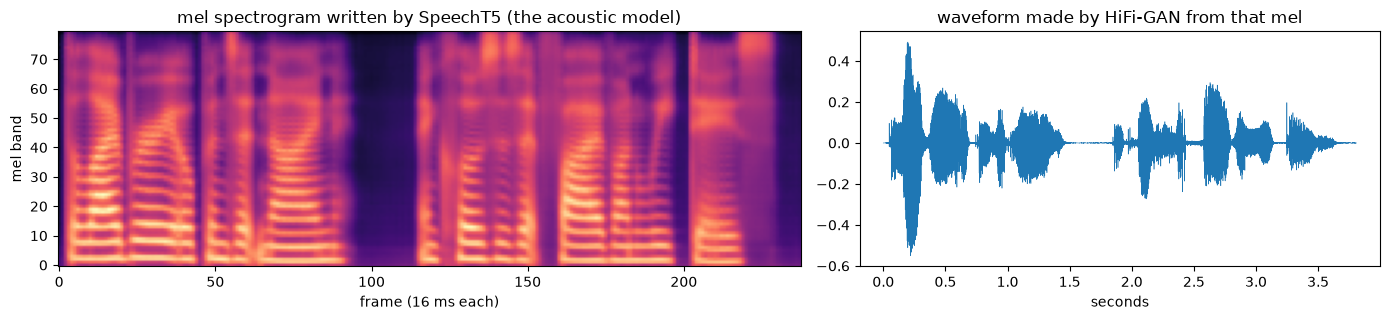

voice 'slt' (US female, CMU ARCTIC x-vector):


In [12]:
from transformers import SpeechT5Processor, SpeechT5ForTextToSpeech, SpeechT5HifiGan
t5p = SpeechT5Processor.from_pretrained("microsoft/speecht5_tts")
t5 = SpeechT5ForTextToSpeech.from_pretrained("microsoft/speecht5_tts").eval()
hifi = SpeechT5HifiGan.from_pretrained("microsoft/speecht5_hifigan").eval()
print("SpeechT5: %.0f M parameters | HiFi-GAN: %.1f M parameters" % (sum(p.numel() for p in t5.parameters()) / 1e6, sum(p.numel() for p in hifi.parameters()) / 1e6))

# the 7 corpus voices: average the x-vectors of all utterances of a speaker, then renormalise to unit length
xz = zipfile.ZipFile(hf_hub_download("Matthijs/cmu-arctic-xvectors", "spkrec-xvect.zip", repo_type="dataset"))
acc_v = {}
for n in xz.namelist():
    m = re.search(r"cmu_us_(\w+)_arctic", n)
    if m and n.endswith(".npy"): acc_v.setdefault(m.group(1), []).append(np.load(io.BytesIO(xz.read(n))))
VOICE = {k: F.normalize(torch.tensor(np.mean([v / np.linalg.norm(v) for v in vs], 0)), dim=-1) for k, vs in acc_v.items()}
DESC = {"bdl": "US male", "slt": "US female", "jmk": "Canadian male", "awb": "Scottish male", "rms": "US male", "clb": "US female", "ksp": "Indian male"}
print({k: "%s (%d utterances)" % (DESC[k], len(v)) for k, v in sorted(acc_v.items())})

@torch.no_grad()
def speak(text, xvec, seed=0, return_mel=False):
    torch.manual_seed(seed)                                   # SpeechT5's decoder prenet uses dropout at inference
    ids = t5p(text=text, return_tensors="pt")["input_ids"]
    mel = t5.generate_speech(ids, xvec.reshape(1, -1))        # without a vocoder: the mel spectrogram, shape (frames, 80)
    wav = hifi(mel).squeeze().numpy()                         # the vocoder: mel -> 16 kHz waveform
    return (mel, wav) if return_mel else wav

SENT = ["The library opens at nine and closes at five on weekdays.",
        "Please remember to bring a warm jacket because the evening will be cold.",
        "She planted three tomato seeds in a small pot near the kitchen window.",
        "A neural network learns by adjusting its weights to reduce an error.",
        "The train to the coast leaves from the second platform every hour.",
        "He painted the old fence blue and the children helped with the gate.",
        "Scientists measured the temperature of the lake at different depths.",
        "Fresh bread and strong coffee were waiting on the table this morning."]
t0 = time.time(); mel, wav = speak(SENT[0], VOICE["slt"], return_mel=True); dt = time.time() - t0
print("'%s'\n -> mel %s, waveform %.2f s of audio in %.2f s of compute (real-time factor %.2f; below 1 is faster than real time)" % (SENT[0], tuple(mel.shape), len(wav) / 16000, dt, dt / (len(wav) / 16000)))
fig, ax = plt.subplots(1, 2, figsize=(14, 3.3), gridspec_kw={"width_ratios": [2, 1.4]})
ax[0].imshow(mel.numpy().T, origin="lower", aspect="auto", cmap="magma"); ax[0].set_title("mel spectrogram written by SpeechT5 (the acoustic model)"); ax[0].set_xlabel("frame (16 ms each)"); ax[0].set_ylabel("mel band")
ax[1].plot(np.arange(len(wav)) / 16000, wav, lw=0.4); ax[1].set_title("waveform made by HiFi-GAN from that mel"); ax[1].set_xlabel("seconds")
plt.tight_layout(); plt.show()
play(wav, 16000, "voice 'slt' (US female, CMU ARCTIC x-vector):")

### 4.2 Listening-free evaluation: round-trip WER

Subjective listening tests (mean opinion score, MOS) are the gold standard for naturalness but need people. A cheap proxy for **intelligibility** is the **round trip**: synthesise a sentence, transcribe it with an independent ASR system, and compute the WER against the original text. If a good recogniser cannot understand the synthetic speech, people probably struggle too. Caveats: the recogniser has a strong language model and may "repair" slightly wrong speech, and the round trip says nothing about naturalness, emotion or voice quality. We use Whisper-base as the judge on 8 sentences in one voice and 4 in another, add a control with a **random speaker vector** (a voice that does not exist, 3 sentences) and then try four sentences chosen to be hard for a text frontend: numbers, a time, an abbreviation, rare place names and a tongue twister.

In [13]:
SPEECH = {}
def say(voice, i):                                     # memoised: voice name, sentence index
    if (voice, i) not in SPEECH: SPEECH[(voice, i)] = speak(SENT[i], VOICE[voice], seed=i)
    return SPEECH[(voice, i)]

t0 = time.time(); rt_rows = {}
for v in ["slt", "bdl"]:
    nS = len(SENT) if v == "slt" else 4
    hyp = asr_whisper("openai/whisper-base", [say(v, i) for i in range(nS)])
    rt_rows["voice %s (%s), %d sentences" % (v, DESC[v], nS)] = wer([norm(x) for x in SENT[:nS]], [norm(h) for h in hyp])
g = torch.Generator().manual_seed(0); RAND_V = F.normalize(torch.randn(512, generator=g), dim=-1)
hyp = asr_whisper("openai/whisper-base", [speak(SENT[i], RAND_V, seed=i) for i in range(3)])
rt_rows["random speaker vector (first 3 sentences)"] = wer([norm(s) for s in SENT[:3]], [norm(h) for h in hyp])
hyp = asr_whisper("openai/whisper-tiny", [say("slt", i) for i in range(len(SENT))])
rt_rows["voice slt, judged by whisper-tiny"] = wer([norm(s) for s in SENT], [norm(h) for h in hyp])
print(pd.Series(rt_rows, name="round-trip WER").round(3).to_string())
print("synthesis + recognition took %.0f s" % (time.time() - t0))

HARD = ["Doctor Nguyen arrived at 4:30 on March 3rd.", "The GPU has 24 GB of VRAM.", "Reykjavik and Ljubljana are both capital cities.", "She sells sea shells by the sea shore."]
heard = asr_whisper("openai/whisper-base", [speak(h, VOICE["slt"], seed=7) for h in HARD])
for h, o in zip(HARD, heard): print("\ntext :", h, "\nheard:", o)
play(say("bdl", 1), 16000, "voice 'bdl' (US male): " + SENT[1])

voice slt (US female), 8 sentences           0.000
voice bdl (US male), 4 sentences             0.041
random speaker vector (first 3 sentences)    0.054
voice slt, judged by whisper-tiny            0.010
synthesis + recognition took 35 s



text : Doctor Nguyen arrived at 4:30 on March 3rd. 
heard: Dr. Glyan arrived at Unmarch-Eard.

text : The GPU has 24 GB of VRAM. 
heard: The goo has G of RAM.

text : Reykjavik and Ljubljana are both capital cities. 
heard: Rakeshavik and Najib Aljana are both capital cities.

text : She sells sea shells by the sea shore. 
heard: She sells seashells by the seashore.
voice 'bdl' (US male): Please remember to bring a warm jacket because the evening will be cold.


**Reading.** The synthetic speech is highly intelligible to an independent recogniser: round-trip WER of 0.0 % for voice *slt* (8 sentences), 4.1 % for voice *bdl* (4 sentences, about two words) and 1.0 % when Whisper-tiny judges *slt*, so the differences between the voices are within noise. A random speaker vector, a voice that does not exist, gives 5.4 % on the three sentences it was tried on: the acoustic model copes with an off-distribution vector but a little less well. The sentences that stress the **text frontend** fail visibly: `4:30` and `March 3rd` become `Unmarch-Eard`, `GPU` and `24 GB` become `goo` and `G`, and unfamiliar place names are mangled, while the tongue twister is fine. Part of that may be the judge's difficulty with rare names, so a round trip finds problems but does not say which stage is at fault. This model reads characters, so numbers, dates and abbreviations should be expanded to words before synthesis in a real system, and rare names need a pronunciation dictionary. Speed: about 2.1 s of compute for 3.8 s of audio on 2 threads (real-time factor 0.55, including some first-call overhead). Caveat: a few sentences and one judge; round-trip WER says nothing about naturalness or prosody.

## 5. Speech-to-speech translation as a cascade

The simplest way to translate speech is to chain the three systems we already have: **ASR** (speech to source text) then **machine translation** (MT, source text to target text) then **TTS** (target text to speech). Its strengths are modularity and the ability to inspect and fix every stage; its weaknesses are that **errors accumulate** (a misheard word is translated confidently) and that prosody, emotion and the speaker's identity are lost at the text bottleneck. Newer *direct* models skip the text; Whisper itself blurs the line because its decoder can output English text directly from foreign speech.

New pieces, both open:

* **Opus-MT** (Tiedemann and Thottingal, 2020, [ACL Anthology](https://aclanthology.org/2020.eamt-1.61/)): small Marian transformer translation models, one per language pair, trained on the OPUS parallel corpora; we use `Helsinki-NLP/opus-mt-en-{es,fr,de}` and `opus-mt-es-en` (Apache 2.0 on the model cards, CC BY 4.0 for en-de; [model card](https://huggingface.co/Helsinki-NLP/opus-mt-en-es)).
* **MMS-TTS** (Pratap et al., 2023, [arXiv 2305.13516](https://arxiv.org/abs/2305.13516)): VITS-based single-voice TTS models for over 1100 languages; we use `facebook/mms-tts-{eng,spa,fra,deu}` (CC BY-NC 4.0, non-commercial; [model card](https://huggingface.co/facebook/mms-tts-spa)).

First we make the foreign-language clips: translate four of our sentences to Spanish, French and German with Opus-MT and speak them with MMS-TTS. They are synthetic voices, which is a limitation (clean, uniform audio), but they give us known references in three languages with no recordings of real people.

In [14]:
from transformers import MarianMTModel, MarianTokenizer, VitsModel, AutoTokenizer
_M, _V = {}, {}
@torch.no_grad()
def translate(texts, src, tgt):
    name = "Helsinki-NLP/opus-mt-%s-%s" % (src, tgt)
    if name not in _M: _M[name] = (MarianTokenizer.from_pretrained(name), MarianMTModel.from_pretrained(name).eval())
    tok, m = _M[name]
    return tok.batch_decode(m.generate(**tok(texts, return_tensors="pt", padding=True), num_beams=4, max_new_tokens=120), skip_special_tokens=True)

@torch.no_grad()
def mms(text, lang, seed=0):                              # lang: eng, spa, fra, deu
    if lang not in _V: _V[lang] = (AutoTokenizer.from_pretrained("facebook/mms-tts-" + lang), VitsModel.from_pretrained("facebook/mms-tts-" + lang).eval())
    tok, m = _V[lang]; torch.manual_seed(seed)
    return m(**tok(text, return_tensors="pt")).waveform[0].numpy()

N5 = 4; LANGS = {"es": "spa", "fr": "fra", "de": "deu"}
t0 = time.time(); text_tr, clips = {}, {"en": [say("slt", i) for i in range(N5)]}
for l, l3 in LANGS.items():
    text_tr[l] = translate(SENT[:N5], "en", l)
    clips[l] = [mms(t, l3, seed=i) for i, t in enumerate(text_tr[l])]
print("making 12 foreign clips took %.0f s" % (time.time() - t0))
for l in LANGS: print(l, "|", text_tr[l][0])
play(clips["es"][0], 16000, "Spanish clip (MMS-TTS):")

# ---- language identification: Whisper's first decoder step is a distribution over language tokens ----
@torch.no_grad()
def lang_probs(name, a, top=2):
    proc, m = whisper(name)
    f = proc(a, sampling_rate=16000, return_tensors="pt").input_features
    sot = proc.tokenizer.convert_tokens_to_ids("<|startoftranscript|>")
    lg = m(input_features=f, decoder_input_ids=torch.tensor([[sot]])).logits[0, -1]
    ids = m.generation_config.lang_to_id
    pr = lg[list(ids.values())].softmax(-1); names = [k.strip("<|>") for k in ids]
    return [(names[i], float(pr[i])) for i in pr.argsort(descending=True)[:top]]

rows = []
for name in ["openai/whisper-tiny", "openai/whisper-base"]:
    for l, cl in clips.items():
        for i, a in enumerate(cl):
            (p1, q1), (p2, q2) = lang_probs(name, a)
            rows.append(dict(model=name.split("/")[1], true=l, predicted=p1, confidence=q1, second=p2, ok=(p1 == l)))
lid = pd.DataFrame(rows)
display(lid.groupby(["model", "true"]).agg(accuracy=("ok", "mean"), mean_confidence=("confidence", "mean")).round(2).unstack(0))
for k in ["digital silence", "loud white noise"]:
    print("language id on %-18s ->" % k, [(p, round(q, 2)) for p, q in lang_probs("openai/whisper-base", nospeech[k])])

making 12 foreign clips took 15 s
es | La biblioteca abre a las nueve y cierra a las cinco de la semana.
fr | La bibliothèque ouvre à neuf heures et ferme à cinq heures en semaine.
de | Die Bibliothek öffnet um neun Uhr und schließt an Wochentagen um fünf Uhr.
Spanish clip (MMS-TTS):


accuracy              mean_confidence             
model whisper-base whisper-tiny    whisper-base whisper-tiny
true                                                        
de             1.0          1.0            1.00         0.99
en             1.0          1.0            1.00         1.00
es             1.0          1.0            0.99         0.97
fr             1.0          1.0            1.00         0.99

language id on digital silence    -> [('en', 0.36), ('cy', 0.21)]


language id on loud white noise   -> [('nn', 0.46), ('en', 0.25)]


**Reading.** Whisper identifies the language of all 16 clips correctly, with both model sizes (English, Spanish, French and German, 4 clips each) and with mean confidence between 0.97 and 1.00. This is the easy case: clean audio from synthetic voices, long sentences and four very different languages; mixed-language speech, short utterances, close languages (Spanish and Portuguese, Norwegian and Danish) and noise are harder, and the silence and noise results above show that the model has no "no language" option. To **translate to English**, Whisper-base gives WER 43 % (Spanish), 61 % (French) and 76 % (German) against the original English sentences, and Whisper-small 33 %, 37 % and 37 %. These include the loss from the first machine translation (the originals went English to X before synthesis, so even a perfect system has an error floor, measured below as about 22 % for Spanish), and 4 sentences per language is a small sample, but the order is clear: the larger model is much better, and the direct translate task of a small Whisper is weak.

### 5.1 Translating to English: Whisper's own task versus the cascade

Whisper can be told `task="translate"` and writes English text straight from foreign speech. We compare it with the explicit **cascade** on the Spanish clips, scoring against the original English sentence that started the chain (a back-translation: the original English went through machine translation, speech synthesis, and now recognition plus translation again, so even a perfect system loses something at the first machine translation). The stages are:

* **A**: English speech (SpeechT5, voice slt);
* **B**: Whisper-base transcript of A;
* **C**: Spanish text, Opus-MT translation of B;
* **D**: Spanish speech, MMS-TTS of C. *This is the output of a speech-to-speech translator*;
* **E**: Whisper-small transcript of D in Spanish (is the output speech intelligible?);
* **F**: English text, Opus-MT translation of E (does the meaning survive?).

Baselines: a **text-only** round trip (English to Spanish to English with no speech at all) isolates the cost of machine translation, and Whisper's direct translate task on D.

model,whisper-base,whisper-small
language,,
de,0.755,0.367
es,0.429,0.327
fr,0.612,0.367


E vs C: Spanish ASR word error rate on the generated Spanish speech = 0.113
B  ASR only (English text vs reference)    0.000
C->F text-only round trip, no speech       0.224
F  full cascade, back to English           0.224
Whisper translate (base) on D              0.429
Whisper translate (small) on D             0.327

A  (speech) ->  B: Please remember to bring a warm jacket because the evening will be cold. 
C (Spanish) : Por favor, recuerde traer una chaqueta caliente porque la noche estará fría. 
E (heard)   : Por favor recuerde traer una chaqueta caliente porque la noche estará fría. 
F (English) : Please remember to bring a warm jacket because the night will be cold. 
reference   : Please remember to bring a warm jacket because the evening will be cold.

A  (speech) ->  B: A neural network learns by adjusting its weights to reduce an error. 
C (Spanish) : Una red neuronal aprende ajustando sus pesos para reducir un error. 
E (heard)   : Una red neuronada pre-deajustando sus peso

cascade took 28 s


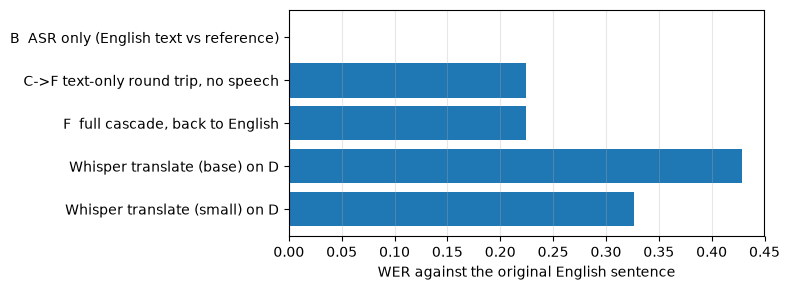

In [15]:
t0 = time.time(); ref5 = [norm(s) for s in SENT[:N5]]
# whisper translate task, all three languages, two model sizes
rows = []
for name in ["openai/whisper-base", "openai/whisper-small"]:
    for l in LANGS:
        hyp = asr_whisper(name, clips[l], language=l, task="translate")
        rows.append(dict(model=name.split("/")[1], language=l, WER_vs_original_English=round(wer(ref5, [norm(h) for h in hyp]), 3)))
direct = pd.DataFrame(rows).pivot(index="language", columns="model", values="WER_vs_original_English"); display(direct)

# the cascade A -> F
B = asr_whisper("openai/whisper-base", clips["en"])
C = translate(B, "en", "es")
D = [mms(t, "spa", seed=i) for i, t in enumerate(C)]
E = asr_whisper("openai/whisper-small", D, language="es")
Fb = translate(E, "es", "en")
text_only = translate(translate(SENT[:N5], "en", "es"), "es", "en")
stage = {"B  ASR only (English text vs reference)": wer(ref5, [norm(x) for x in B]),
         "C->F text-only round trip, no speech": wer(ref5, [norm(x) for x in text_only]),
         "F  full cascade, back to English": wer(ref5, [norm(x) for x in Fb]),
         "Whisper translate (base) on D": wer(ref5, [norm(x) for x in asr_whisper("openai/whisper-base", D, language="es", task="translate")]),
         "Whisper translate (small) on D": wer(ref5, [norm(x) for x in asr_whisper("openai/whisper-small", D, language="es", task="translate")])}
asr_es = wer([norm(x) for x in C], [norm(x) for x in E])
print("E vs C: Spanish ASR word error rate on the generated Spanish speech = %.3f" % asr_es)
print(pd.Series(stage, name="WER vs original English").round(3).to_string())
for i in [1, 3]:
    print("\nA  (speech) ->  B:", B[i], "\nC (Spanish) :", C[i], "\nE (heard)   :", E[i], "\nF (English) :", Fb[i], "\nreference   :", SENT[i])
play(D[1], 16000, "D: the translated Spanish speech for sentence 2:")
print("cascade took %.0f s" % (time.time() - t0))
fig, ax = plt.subplots(figsize=(8, 3)); ax.barh(list(stage)[::-1], list(stage.values())[::-1], color="C0"); ax.set_xlabel("WER against the original English sentence"); ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()

**Reading.** The cascade works end to end on these four sentences. Stage B (Whisper-base on the English speech) is exact (WER 0.0 %); the full path English speech, Spanish text, Spanish speech, Spanish transcript, English text returns text that is 22.4 % away from the original, and the **text-only** round trip with no speech at all is 22.4 % as well: on this sample almost all of the loss is in machine translation (the same meaning put in other words, such as `evening` becoming `night`) and the speech stages add little in total, although the Spanish recogniser mis-heard the generated Spanish speech with an 11.3 % word error rate over the four sentences (`red neuronada pre-deajustando` for `red neuronal aprende ajustando`), which then propagated into the English (`A neuron network pre-deadjustable its weights`): the signature error accumulation of cascades. Both totals being equal is partly coincidence (different words are wrong in each); with four sentences nothing finer than that should be read from it. Whisper's own translate task applied to the generated Spanish speech is clearly worse than the cascade here (42.9 % for base and 32.7 % for small against 22.4 %), which is why cascades remain the practical baseline.

## 6. Speaker embeddings, similarity and voice cloning

### 6.1 What a speaker embedding is

A **speaker embedding** maps a clip of any length to a fixed vector such that clips from the same person are close and clips from different people are far, whatever is said. **X-vectors** (Snyder et al., 2018) pool frame-level features over time into one vector with a statistics layer. **ECAPA-TDNN** (Desplanques et al., 2020, [arXiv 2005.07143](https://arxiv.org/abs/2005.07143)) improves on them with channel attention, multi-scale features and aggregation across layers, and is trained with an angular-margin loss on thousands of speakers (VoxCeleb). We use SpeechBrain's pre-trained [`speechbrain/spkrec-ecapa-voxceleb`](https://huggingface.co/speechbrain/spkrec-ecapa-voxceleb) (192 numbers per clip, Apache 2.0 licence for the code and model; the VoxCeleb training data has its own terms) and compare clips by **cosine similarity**. Two roles, deliberately given to **different** models so the test is not circular:

* ECAPA is the **judge**: how similar do two voices sound?
* the x-vector extractor [`speechbrain/spkrec-xvect-voxceleb`](https://huggingface.co/speechbrain/spkrec-xvect-voxceleb) (512 numbers, Apache 2.0) is the model SpeechT5's voices were made with, so it is the **enrolment** model that turns a reference clip into a voice vector for the TTS.

First a sanity check on **real** speech: can ECAPA tell speakers apart? On the six FSDD speakers (who released their recordings openly; all we do is compute similarity, and each clip is a single 0.5 s word, a hard case). The LibriSpeech copy we use has only one reader, so it cannot serve for this test.

Failed to detect torchaudio major version; unsure how to check your setup. We recommend that you keep torchaudio up-to-date.


Failed to detect torchaudio major version; unsure how to check your setup. We recommend that you keep torchaudio up-to-date.


FSDD: 120 clips of 6 speakers, 1140 same-speaker pairs, 6000 different-speaker pairs
mean cosine same speaker 0.51 | different speakers 0.19 | equal error rate 7.4 % at threshold 0.34
speaker identification from one 0.5 s digit (leave-one-out, 6 speakers, chance 17 %): 100 %
embedding took 3 s


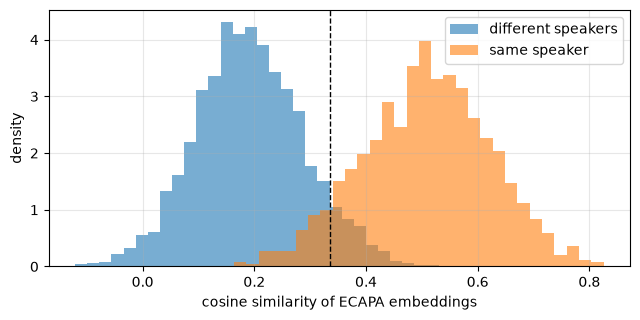

In [16]:
try:
    import torchaudio                                   # on Colab this is the real one, preinstalled next to torch
except Exception:                                       # a missing or mismatched torchaudio: SpeechBrain only needs the module to exist for inference
    import sys, types
    _ta = types.ModuleType("torchaudio"); _ta.__version__ = "0.0"
    _ta.list_audio_backends = lambda: []; _ta.set_audio_backend = lambda *a, **k: None; _ta.get_audio_backend = lambda: None
    sys.modules["torchaudio"] = _ta
from speechbrain.inference.speaker import EncoderClassifier
from sklearn.metrics import roc_curve
ecapa = EncoderClassifier.from_hparams(source="speechbrain/spkrec-ecapa-voxceleb", savedir=CACHE + "/ecapa", run_opts={"device": "cpu"})
xvec_net = EncoderClassifier.from_hparams(source="speechbrain/spkrec-xvect-voxceleb", savedir=CACHE + "/xvect", run_opts={"device": "cpu"})

@torch.no_grad()
def emb(model, a): return F.normalize(model.encode_batch(torch.tensor(np.asarray(a, dtype=np.float32))[None]).reshape(-1), dim=-1)

# --- FSDD: six speakers, 8 kHz one-word clips (the LibriSpeech copy has one reader, so it cannot test speaker separation) ---
t0 = time.time(); sp6 = sorted(by_spk); E_f, y_f = [], []
for j, s_ in enumerate(sp6):
    for c in by_spk[s_][:20]: E_f.append(emb(ecapa, to16k(c["audio"], 8000))); y_f.append(j)
E_f = torch.stack(E_f); y_f = np.array(y_f)
S = (E_f @ E_f.T).numpy(); iu = np.triu_indices(len(y_f), 1)
same = y_f[iu[0]] == y_f[iu[1]]; sims = S[iu]
fpr, tpr, thr = roc_curve(same, sims); fnr = 1 - tpr; k = np.argmin(np.abs(fpr - fnr)); eer = (fpr[k] + fnr[k]) / 2
print("FSDD: %d clips of 6 speakers, %d same-speaker pairs, %d different-speaker pairs" % (len(y_f), same.sum(), (~same).sum()))
print("mean cosine same speaker %.2f | different speakers %.2f | equal error rate %.1f %% at threshold %.2f" % (sims[same].mean(), sims[~same].mean(), 100 * eer, thr[k]))
hits = 0
for i in range(len(y_f)):
    cent = torch.stack([F.normalize(E_f[(y_f == j) & (np.arange(len(y_f)) != i)].mean(0), dim=-1) for j in range(6)])
    hits += int((cent @ E_f[i]).argmax()) == y_f[i]
print("speaker identification from one 0.5 s digit (leave-one-out, 6 speakers, chance 17 %%): %.0f %%" % (100 * hits / len(y_f)))
print("embedding took %.0f s" % (time.time() - t0))
fig, ax = plt.subplots(figsize=(6.5, 3.3))
ax.hist(sims[~same], bins=30, alpha=0.6, density=True, label="different speakers"); ax.hist(sims[same], bins=30, alpha=0.6, density=True, label="same speaker")
ax.axvline(thr[k], c="k", ls="--", lw=1); ax.set_xlabel("cosine similarity of ECAPA embeddings"); ax.set_ylabel("density"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Reading.** From a single half-second digit, ECAPA identifies which of the six FSDD speakers is talking 100 % of the time (120 clips, chance is 17 %), the average similarity is 0.51 for the same speaker and 0.19 for different speakers, and the equal error rate (the threshold at which false accepts and false rejects are equally frequent) is 7.4 %. Be careful with the easy part of this result: each FSDD speaker was recorded in one setup, so microphone and room identify the speaker as much as the voice does, and six speakers is a small test. Real speaker-verification systems are evaluated on thousands of speakers in varied conditions; their error rates are higher than this and rise sharply for short, noisy or emotional speech.

### 6.2 Conditioning a TTS on a speaker embedding, and cloning from a reference

SpeechT5 takes its voice from a 512-number vector. Two experiments, **both with synthetic voices only**:

1. **Do five of the corpus voices sound like five different speakers to an independent judge?** We synthesise three sentences per voice and let ECAPA identify the voice of each clip from the *other* sentences (leave one sentence out): a fair test that the embedding carries identity and not the text.
2. **Cloning from a reference.** For each of the five voices we take **one 3 to 4 second synthetic clip** as the "reference recording", enrol it with the x-vector extractor to get a voice vector, ask SpeechT5 to say a **new** sentence with that vector, and check whether the ECAPA judge assigns the result to the right voice. Two controls: the *oracle* (SpeechT5 with the true voice vector, the best this TTS can do) and a *random* vector. Judge centroids are built only from the other two sentences, never from the reference clip.

ECAPA identifies the synthetic voice of a held-out sentence: 15 of 15 (chance 20 %)
mean cosine, same voice different sentences: 0.85 | different voices: 0.37


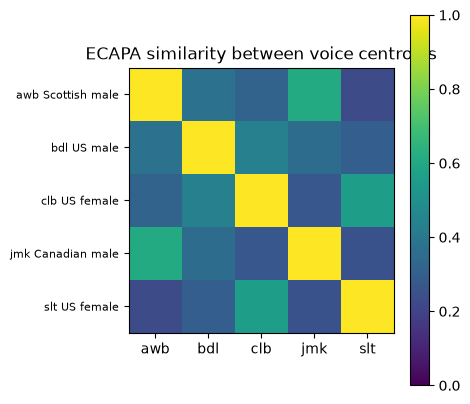

,similarity_to_target,best_other_voice,identified_correctly,xvector_cosine_to_true
kind,,,,
clone,0.83,0.53,5,0.98
oracle,0.88,0.52,5,1.00


random vector control: most similar voice clb with cosine 0.53 (it is nobody)


,voice,sim_target,sim_best_other,correct,xvec_cos_to_true
0,awb,0.84,0.54,True,0.98
1,bdl,0.85,0.41,True,0.97
2,clb,0.90,0.52,True,0.98
3,jmk,0.77,0.59,True,0.97
4,slt,0.80,0.58,True,0.98


cloning experiment took 49 s
target voice jmk (Canadian male):


clone made from one reference clip of jmk:


In [17]:
t0 = time.time(); VN = ["awb", "bdl", "clb", "jmk", "slt"]                                      # five of the seven corpus voices, to keep the run short
EV = {v: [emb(ecapa, say(v, i)) for i in range(3)] for v in VN}                    # 5 voices x 3 sentences
cent = {v: F.normalize(torch.stack(EV[v]).mean(0), dim=-1) for v in VN}
# 1) leave-one-sentence-out identification of the voice
hits = 0
for v in VN:
    for i in range(3):
        c_ = torch.stack([F.normalize(torch.stack([EV[u][j] for j in range(3) if j != i]).mean(0), dim=-1) for u in VN])
        hits += int((c_ @ EV[v][i]).argmax()) == VN.index(v)
print("ECAPA identifies the synthetic voice of a held-out sentence: %d of %d (chance %.0f %%)" % (hits, 3 * len(VN), 100 / len(VN)))
M = torch.stack([cent[v] for v in VN]); SIM = (M @ M.T).numpy()
within = np.mean([float(EV[v][i] @ EV[v][j]) for v in VN for i in range(3) for j in range(i + 1, 3)])
print("mean cosine, same voice different sentences: %.2f | different voices: %.2f" % (within, SIM[~np.eye(len(VN), dtype=bool)].mean()))
fig, ax = plt.subplots(figsize=(4.8, 4.2)); im = ax.imshow(SIM, cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(VN))); ax.set_yticks(range(len(VN))); ax.set_xticklabels(["%s" % v for v in VN]); ax.set_yticklabels(["%s %s" % (v, DESC[v]) for v in VN], fontsize=8)
ax.set_title("ECAPA similarity between voice centroids"); plt.colorbar(im); plt.tight_layout(); plt.show()

# 2) cloning: reference clip (sentence 0) -> x-vector -> new sentence 3
rows = []; cl_audio = {}
for v in VN:
    ref_clip = say(v, 0)
    xv = emb(xvec_net, ref_clip)                                                    # enrolment: 512-d voice vector
    clone = speak(SENT[3], xv, seed=3); oracle = say(v, 3); cl_audio[v] = clone
    # judge centroids from sentences 1 and 2 only (the reference sentence 0 is excluded)
    cents = torch.stack([F.normalize(torch.stack([EV[u][1], EV[u][2]]).mean(0), dim=-1) for u in VN])
    for kind, a in [("clone", clone), ("oracle", oracle)]:
        s_ = cents @ emb(ecapa, a)
        rows.append(dict(voice=v, kind=kind, sim_target=float(s_[VN.index(v)]), sim_best_other=float(np.delete(s_.numpy(), VN.index(v)).max()), correct=int(s_.argmax()) == VN.index(v)))
    rows[-2]["xvec_cos_to_true"] = float(xv @ VOICE[v]); rows[-1]["xvec_cos_to_true"] = 1.0
rnd = speak(SENT[3], RAND_V, seed=3); s_r = torch.stack([F.normalize(torch.stack([EV[u][1], EV[u][2]]).mean(0), dim=-1) for u in VN]) @ emb(ecapa, rnd)
cl = pd.DataFrame(rows)
display(cl.groupby("kind").agg(similarity_to_target=("sim_target", "mean"), best_other_voice=("sim_best_other", "mean"), identified_correctly=("correct", "sum"), xvector_cosine_to_true=("xvec_cos_to_true", "mean")).round(2))
print("random vector control: most similar voice %s with cosine %.2f (it is nobody)" % (VN[int(s_r.argmax())], float(s_r.max())))
display(cl[cl.kind == "clone"][["voice", "sim_target", "sim_best_other", "correct", "xvec_cos_to_true"]].round(2).reset_index(drop=True))
print("cloning experiment took %.0f s" % (time.time() - t0))
play(say("jmk", 3), 16000, "target voice jmk (Canadian male):"); play(cl_audio["jmk"], 16000, "clone made from one reference clip of jmk:")

**Reading.** The embedding does carry voice identity. ECAPA identifies the voice of all 15 held-out synthetic clips (chance 20 %); the average similarity is 0.85 between different sentences of the same voice and 0.37 between different voices. **Cloning from one reference clip works in this setting**: for all 5 voices the clone is closest to its target (similarity 0.83 against 0.53 for the best other voice), the x-vector enrolled from the reference has cosine 0.98 with the true voice vector, and the oracle that uses the true vector scores 0.88, so enrolment from one 3 to 4 second clip loses about 0.05 of the achievable similarity. The random-vector control is close to nobody (best match 0.53). The strong caveats are specific to this being a **best case**: the reference clip comes from the same TTS that then speaks, so there is no channel or noise mismatch; the judge is a model, not a listener, and a high ECAPA similarity does not mean a person would be fooled; and only five voices are involved. A real recording of a person, with a room and a microphone, would give a noisier voice vector, and a general x-vector TTS reproduces timbre but little of the style, so we should expect real clones from this recipe to be recognisable but not convincing; the zero-shot systems below close that gap.

### 6.3 Morphing between voices

Because a voice is just a point in a 512-dimensional space, we can walk between two voices. This is both a nice demonstration that the embedding is *continuous* (there are infinitely many voices between the seven we have, including ones that belong to nobody) and the basic mechanism behind designing a new synthetic voice that does not imitate a real person.

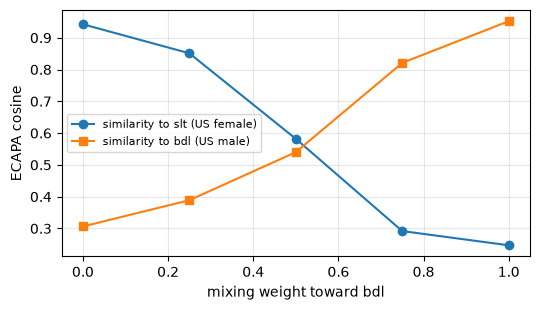

morph took 11 s


In [18]:
t0 = time.time(); lams = [0, 0.25, 0.5, 0.75, 1.0]; ms, mb = [], []
for lam in lams:
    vec = F.normalize((1 - lam) * VOICE["slt"] + lam * VOICE["bdl"], dim=-1)
    e = emb(ecapa, speak(SENT[1], vec, seed=1))
    ms.append(float(e @ cent["slt"])); mb.append(float(e @ cent["bdl"]))
fig, ax = plt.subplots(figsize=(5.5, 3.2)); ax.plot(lams, ms, "o-", label="similarity to slt (US female)"); ax.plot(lams, mb, "s-", label="similarity to bdl (US male)")
ax.set_xlabel("mixing weight toward bdl"); ax.set_ylabel("ECAPA cosine"); ax.grid(alpha=0.3); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
print("morph took %.0f s" % (time.time() - t0))

**Reading.** The embedding space is continuous and the morph behaves smoothly: the similarity to *slt* falls from 0.94 to 0.85, 0.58, 0.29 and 0.25 as the weight moves to *bdl*, while the similarity to *bdl* rises from 0.31 to 0.39, 0.54, 0.82 and 0.95. At a weight of 0.5 the voice is about equally far from both (0.58 and 0.54): it is a voice that belongs to neither, which is the principled way to give a product its own voice without imitating anyone. The transition is not linear: a quarter of the way the voice still sounds like *slt* to the judge, and most of the change happens between 0.5 and 0.75.

### 6.4 Zero-shot cloning with codec language models (explained, not run)

An x-vector is a *summary* of a voice, a few hundred numbers, and a TTS conditioned on it can reproduce broad timbre but little of the speaker's style, accent or recording conditions: our clone above shows the limit. **Zero-shot** systems go further by conditioning on the **audio itself**. **VALL-E** (Wang et al., 2023, [arXiv 2301.02111](https://arxiv.org/abs/2301.02111)) first compresses speech into discrete **codec tokens** with a neural audio codec (the encoder, quantiser and decoder of a neural compression network, see [module 06 of Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/06-audio-and-video-generation/)). It then treats TTS as **language modelling**: a large transformer is trained on 60 000 hours of speech to continue a token sequence, with the phoneme sequence of the target text and a **3 second prompt** of the target speaker's codec tokens as the prefix. The continuation is speech that says the new text *in the prompt's voice*, and, because the prompt carries everything, also in its recording environment and often its emotion, with no per-speaker training: "zero-shot". This is the same recipe as the large language models of [module 10 of Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/10-gpt-from-scratch/), applied to audio tokens.

We do not run one here: the original is not released, open re-implementations are large (and several have non-commercial weights licences, so check before use), and, honestly, what it demonstrates is exactly what section 7 is about. Three seconds of anyone's speech, from a voicemail, a video or a podcast, are enough for the quality to fool listeners in the papers' own tests, which is why consent is the central question and not a footnote.

## 7. Ethics, consent, fraud, detection, watermarking and law

Everything in sections 4 to 6 is a dual-use technology. The good uses are real: reading aloud for people with visual impairments, giving a voice back to someone who lost theirs to illness (a person can "bank" their voice beforehand), dubbing and accessibility, language learning. The harmful uses are real too:

* **Fraud.** A cloned voice defeats the oldest identity check there is, "it sounded like my daughter". Consumer-protection agencies have warned about the **family emergency scam**, where a caller with a cloned voice asks a relative for urgent money ([NPR report on the FTC warning, 2023](https://www.npr.org/2023/03/22/1165448073/that-panicky-call-from-a-relative-it-could-be-a-thief-using-a-voice-clone-ftc-warns)), and about bank and corporate "voice authentication", which a good clone can attack. In 2024 robocalls imitating a political leader's voice, urging people not to vote, led the US Federal Communications Commission to rule that AI-generated voices are "artificial" voices under the telephone-consumer law ([FCC declaratory ruling 24-17](https://docs.fcc.gov/public/attachments/FCC-24-17A4.pdf)).
* **Non-consensual imitation and harassment**, including the use of an actor's, a singer's or a private person's voice without permission; **disinformation**, since a recording used to be evidence and no longer is by itself.
* **Privacy.** A voice is **biometric** data: under the European General Data Protection Regulation, voice processed to identify a person is a special category with strict conditions, and recordings in public datasets were often released without people picturing this use.

**Our rules in this notebook, and a sensible default for you.** (1) Clone only voices whose owner has given explicit, informed consent for that specific use; a licence on a dataset (such as CC BY) allows reuse of the *recording*, not necessarily the imitation of the *person*. (2) Prefer synthetic or designed voices: every voice here is a corpus voice released for TTS research or a blend of such voices. (3) Disclose synthetic audio. (4) Do not use a voice as a password, and agree a family or company **out-of-band check** (call back on a known number, a code word) for any urgent request for money or secrets.

### 7.1 Detection: a toy that works, and why it will not save you

A **detector** is a classifier for "real recording or generated". We build the simplest one: the mean and standard deviation of the 40 log-mel bands over the first 2.5 s of a clip (80 numbers), then a logistic regression. Real class: LibriSpeech clips (a single reader, a real limitation). Synthetic class: our SpeechT5 clips. We split **by voice** for the synthetic class (no SpeechT5 voice appears in both training and test; the single real reader is split by clip), and then test four things the detector never saw: held-out real clips, held-out SpeechT5 clips, the **same real clips squeezed to 8 kHz and back** (an everyday transformation: a phone call), and clips from a **different generator**, the MMS-TTS English model (VITS architecture, a different design than SpeechT5 + HiFi-GAN).

In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold
N25 = 40000
def det_feat(a):
    a = np.asarray(a[:N25], dtype=np.float32); a = np.pad(a, (0, N25 - len(a)))
    m = logmel(a, 16000, 512, 160, 40).numpy(); return np.concatenate([m.mean(0), m.std(0)])

real = [("reader", c["audio"]) for c in ls_all if c["dur"] >= 2.5]
syn = [(k[0], a) for k, a in SPEECH.items() if len(a) >= 24000]
Xr = np.array([det_feat(a) for _, a in real]); Xs = np.array([det_feat(a) for _, a in syn])
fold_r = np.arange(len(real)) % 5; VOICES_ = sorted({g for g, _ in syn}); fold_s = np.array([VOICES_.index(g) % 5 for g, _ in syn])
X = np.vstack([Xr, Xs]); y = np.r_[np.zeros(len(Xr)), np.ones(len(Xs))]; fold = np.r_[fold_r, fold_s]
print("real clips: %d (1 reader) | synthetic SpeechT5 clips: %d (%d voices)" % (len(Xr), len(Xs), len(VOICES_)))

t0 = time.time()
eng = [mms(sx, "eng", seed=i) for i, sx in enumerate(SENT[:4])]; Xv = np.array([det_feat(a) for a in eng])        # a different generator (VITS)
phone = [resample_poly(resample_poly(a, 1, 2), 2, 1).astype(np.float32) for _, a in real]; Xp = np.array([det_feat(a) for a in phone])   # band-limited real speech
accs, fl = [], []
for f_ in range(5):
    tr, te = np.where(fold != f_)[0], np.where(fold == f_)[0]
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.3, max_iter=2000)).fit(X[tr], y[tr])
    te_r, te_s = te[y[te] == 0], te[y[te] == 1]
    accs.append(clf.score(X[te], y[te]))
    fl.append([clf.predict(X[te_r]).mean(), clf.predict(X[te_s]).mean(), clf.predict(Xp[te_r]).mean(), clf.predict(Xv).mean()])
fl = np.array(fl)
res = pd.Series({"held-out accuracy (5 folds, voices held out)": np.mean(accs),
                 "real clips flagged as synthetic": fl[:, 0].mean(),
                 "SpeechT5 clips flagged (should be 1)": fl[:, 1].mean(),
                 "real clips through an 8 kHz phone-like channel flagged": fl[:, 2].mean(),
                 "MMS-TTS (VITS) clips flagged (unseen generator, should be 1)": fl[:, 3].mean()})
print(res.round(2).to_string()); print("detector experiment took %.0f s" % (time.time() - t0))

real clips: 65 (1 reader) | synthetic SpeechT5 clips: 24 (5 voices)


held-out accuracy (5 folds, voices held out)                    0.93
real clips flagged as synthetic                                 0.00
SpeechT5 clips flagged (should be 1)                            0.75
real clips through an 8 kHz phone-like channel flagged          1.00
MMS-TTS (VITS) clips flagged (unseen generator, should be 1)    1.00
detector experiment took 3 s


**Reading.** Held-out accuracy is 93 %: real clips are never flagged (0 %) and 75 % of the SpeechT5 clips of unseen voices are. The two remaining numbers are the lesson. The unseen generator (MMS-TTS, VITS) is flagged 100 % of the time, which looks like excellent generalisation, but the **real** clips squeezed through an 8 kHz phone-like channel are also flagged 100 % of the time: the detector has learned "this does not look like the one reader's full-band recording" rather than "this was generated". Any change of microphone, codec, loudness or language would flip it, and our real class has a single reader, a much poorer test than a real detector faces. Detectors for generated speech are trained on many generators and recording conditions, and still lose accuracy on a generator that appears after training, which is why they are one signal among several and never proof.

### 7.2 Watermarking: marking generated audio at the source

The opposite strategy is for the **generator** to leave a hidden mark that a detector looks for with a secret key. The classic **spread-spectrum** watermark adds a very quiet pseudo-random noise sequence $w$ determined by a secret key $k$ to the audio $a$: $a' = a + \alpha\, w_k$. To test a clip, correlate it with the sequence for the key: the statistic $z = a'\!\cdot w_k / \lVert a' \rVert$ is approximately a standard normal number if the mark is absent (so $z > 4$ has odds of about 1 in 30 000 of happening by chance) and grows like $\alpha\sqrt{N}$ (with $N$ the number of samples) if present. We embed at a signal-to-mark ratio of 30 dB in 8 SpeechT5 clips and then attack the marked audio in ways that happen to audio in real life. Learned watermarks such as AudioSeal (San Roman et al., 2024, [arXiv 2401.17264](https://arxiv.org/abs/2401.17264)) are trained against such attacks and can localise the marked parts inside longer audio; this toy only shows the principle and the first obstacles.

In [20]:
def wm_seq(n, key): return np.random.default_rng(key).standard_normal(n).astype(np.float32)
def wm_embed(a, key, snr_db=30):
    return a + wm_seq(len(a), key) * np.sqrt((a ** 2).mean() / 10 ** (snr_db / 10))
def wm_z(a, key): return float(a @ wm_seq(len(a), key) / np.linalg.norm(a))
def fit_len(a, n): return np.pad(a, (0, max(0, n - len(a))))[:n]

clips_wm = [say("slt", i)[:40000] for i in range(8)]; KEY = 1234
marked = [wm_embed(a, KEY) for a in clips_wm]
attacks = {"no mark (control)": lambda a, o: o,
           "marked, untouched": lambda a, o: a,
           "marked, wrong key checked": lambda a, o: a,
           "volume x0.3": lambda a, o: 0.3 * a,
           "add noise, 20 dB SNR": lambda a, o: add_white(a, 20, 1),
           "8 kHz channel (low-pass + resample)": lambda a, o: fit_len(resample_poly(resample_poly(a, 1, 2), 2, 1), len(a)).astype(np.float32),
           "start trimmed by 1 sample": lambda a, o: fit_len(a[1:], len(a)),
           "speed change 3 %": lambda a, o: fit_len(resample_poly(a, 100, 103), len(a)).astype(np.float32)}
rows = []
for name, fn in attacks.items():
    zs = [wm_z(fn(m, o), 999 if "wrong" in name else KEY) for m, o in zip(marked, clips_wm)]
    rows.append(dict(condition=name, mean_z=round(float(np.mean(zs)), 1), detected=int(np.sum(np.array(zs) > 4)), out_of=8))
display(pd.DataFrame(rows))

,condition,mean_z,detected,out_of
0,no mark (control),-0.4,0,8
1,"marked, untouched",5.9,8,8
2,"marked, wrong key checked",0.6,0,8
3,volume x0.3,5.9,8,8
4,"add noise, 20 dB SNR",5.9,8,8
5,8 kHz channel (low-pass + resample),2.7,0,8
6,start trimmed by 1 sample,-0.3,0,8
7,speed change 3 %,-0.3,0,8


**Reading.** Without the mark the statistic is near zero (mean $-0.4$, 0 of 8 clips detected at $z > 4$); with it, $z \approx 5.9$ and 8 of 8 are detected; with the wrong key it is 0.6 (0 of 8), so only the key holder can read the mark. It survives a volume change (the statistic is scale-invariant) and additive noise at 20 dB signal-to-noise ratio, 10 dB louder than the mark itself, because noise is uncorrelated with the key. It does **not** survive being sent through an 8 kHz channel (mean $z = 2.7$, 0 of 8), which removes half of the mark's energy, nor a one-sample shift or a 3 % speed change (mean $z = -0.3$): the key sequence no longer lines up with the audio, and a naive detector would have to search over every shift and speed. A 30 dB mark of white noise is also faintly audible as hiss. These are the problems that learned watermarks are trained to solve, and they still can be removed by a determined attacker (for example by re-synthesising the speech), so a watermark helps honest providers and accountability but does not stop a malicious one.

### 7.3 The legal frame

Law is moving quickly and differs by country; this is a map, not legal advice.

* **European Union.** The Artificial Intelligence Act ([Regulation (EU) 2024/1689](https://eur-lex.europa.eu/eli/reg/2024/1689/oj)), [Article 50](https://artificialintelligenceact.eu/article/50/), obliges providers of systems that generate synthetic audio to mark their outputs in a machine-readable way and deployers of deepfakes to disclose that the content is artificially generated or manipulated. The General Data Protection Regulation applies to voice as personal (and, when used for identification, biometric) data.
* **United States.** The [FCC ruling](https://docs.fcc.gov/public/attachments/FCC-24-17A4.pdf) above makes AI-voice robocalls subject to the telephone-consumer law, which generally requires the recipient's prior consent. Several states have added rights over one's voice and likeness.
* **Everywhere.** Fraud, impersonation and harassment are already crimes whatever tool is used, and rights over a person's voice and image exist in many legal systems; platform terms of the model providers add further limits (several open TTS models ship with a non-commercial or "no impersonation" licence).

As a practitioner: obtain written consent for any cloned voice, keep a record of it, label generated audio, watermark what you generate when you can, treat detectors as one weak signal, and design systems so that **a voice alone never authorises anything**.

## 8. Key takeaways, exercises, references

### Key takeaways

1. **Speech models work on log-mel features**: a waveform is cut into 25 ms windows, turned into energies on a mel scale and logged; ASR maps that image to text, TTS maps text to it and a vocoder maps it back to audio.
2. **CTC** removes the need for frame-level labels by summing over every alignment with a blank symbol; it trains with a dynamic program, produces peaky posteriors, and has no language knowledge, so decoding with a lexicon or language model helps. A from-scratch recogniser is accurate on voices it has heard and degrades on an unfamiliar speaker (section 2).
3. **Pre-trained recognisers are the right tool for real work.** Whisper, trained on a very large and varied web corpus, is far more robust than anything we can train on a laptop, but robust is not infallible: noise raises WER, accents matter, and on speechless input it can **hallucinate** fluent text. Add a voice-activity gate and check the model's no-speech signals (section 3).
4. **TTS = text frontend + acoustic model + vocoder**, and its quality can be probed without listening by round-trip WER, with the caveat that the judge may repair errors and says nothing about naturalness (section 4).
5. **Cascades are modular but accumulate errors**; speech translation quality is bounded by its weakest stage, and the text bottleneck drops the speaker's voice and prosody (section 5).
6. **A voice is a point in an embedding space.** Conditioning a TTS on an embedding gives a rough imitation from one short reference; zero-shot codec language models do far better from three seconds of audio, which is exactly why **consent, disclosure, watermarking and out-of-band verification** are engineering requirements (sections 6 and 7).
7. **Detectors trained on one generator should not be trusted on another**, and a simple watermark survives noise and filtering but not desynchronisation; defence needs several layers, not one model.

### Exercises

1. In section 2, change the beam width from 8 to 1, 2, 4, 16 and plot WER on the unseen speaker. When does widening stop helping? Then change the lexicon bonus $\beta$ and find the value that minimises WER.
2. Train the CTC model with the unseen speaker's *accent group* (the other German-accent speaker, *yweweler*) removed instead of *lucas* removed. Does the error on the held-out speaker change, and what does it tell you about data coverage?
3. Replace the two strided convolutions by a single one (2x downsampling). Check that CTC still trains and compare time and WER. What is the longest transcript per second of audio CTC can represent with 4x downsampling at 10 ms hop?
4. Repeat the noise experiment of section 3.2 with another noise: a 1 kHz tone, or low-pass filtered noise. Does the ranking of the three recognisers change?
5. Run Whisper with `language=None` on the noisy clips and count how often the detected language is wrong at 0 dB. Add a rule based on language-identification confidence to reject such cases.
6. In section 6.2, enrol the clone from the *second* sentence and from a clip padded with 2 s of silence. How sensitive is the cloned voice to the reference?
7. Extend the detector of section 7.1 with a few extra features (spectral flatness, pitch variability) and measure whether it generalises to the VITS clips. Why is "it works on my test set" not the question that matters?
8. Discussion: a bank offers voice authentication to customers. Write the threat model, then list three controls (technical, procedural, legal) you would add.

### References

* Graves, A., Fernández, S., Gomez, F. and Schmidhuber, J. (2006). Connectionist temporal classification: labelling unsegmented sequence data with recurrent neural networks. ICML. [paper](https://www.cs.toronto.edu/~graves/icml_2006.pdf), [doi:10.1145/1143844.1143891](https://doi.org/10.1145/1143844.1143891).
* Hannun, A. (2017). Sequence modeling with CTC. Distill. [distill.pub/2017/ctc](https://distill.pub/2017/ctc/). Hannun, A. Y., Maas, A. L., Jurafsky, D. and Ng, A. Y. (2014). First-pass large vocabulary continuous speech recognition using bi-directional recurrent DNNs. [arXiv 1408.2873](https://arxiv.org/abs/1408.2873).
* Radford, A., Kim, J. W., Xu, T., Brockman, G., McLeavey, C. and Sutskever, I. (2022). Robust speech recognition via large-scale weak supervision (Whisper). [arXiv 2212.04356](https://arxiv.org/abs/2212.04356).
* Baevski, A., Zhou, H., Mohamed, A. and Auli, M. (2020). wav2vec 2.0: a framework for self-supervised learning of speech representations. [arXiv 2006.11477](https://arxiv.org/abs/2006.11477).
* Ao, J. et al. (2021). SpeechT5: unified-modal encoder-decoder pre-training for spoken language processing. [arXiv 2110.07205](https://arxiv.org/abs/2110.07205).
* Kong, J., Kim, J. and Bae, J. (2020). HiFi-GAN: generative adversarial networks for efficient and high fidelity speech synthesis. [arXiv 2010.05646](https://arxiv.org/abs/2010.05646).
* Desplanques, B., Thienpondt, J. and Demuynck, K. (2020). ECAPA-TDNN: emphasized channel attention, propagation and aggregation in TDNN based speaker verification. [arXiv 2005.07143](https://arxiv.org/abs/2005.07143).
* Snyder, D., Garcia-Romero, D., Sell, G., Povey, D. and Khudanpur, S. (2018). X-vectors: robust DNN embeddings for speaker recognition. ICASSP. [doi:10.1109/ICASSP.2018.8461375](https://doi.org/10.1109/ICASSP.2018.8461375).
* Wang, C. et al. (2023). Neural codec language models are zero-shot text to speech synthesizers (VALL-E). [arXiv 2301.02111](https://arxiv.org/abs/2301.02111).
* Tiedemann, J. and Thottingal, S. (2020). OPUS-MT, building open translation services for the world. EAMT. [ACL Anthology](https://aclanthology.org/2020.eamt-1.61/).
* Pratap, V. et al. (2023). Scaling speech technology to 1,000+ languages (MMS). [arXiv 2305.13516](https://arxiv.org/abs/2305.13516).
* Ravanelli, M. et al. (2021). SpeechBrain: a general-purpose speech toolkit. [arXiv 2106.04624](https://arxiv.org/abs/2106.04624).
* San Roman, R., Fernandez, P., Defossez, A. et al. (2024). Proactive detection of voice cloning with localized watermarking (AudioSeal). [arXiv 2401.17264](https://arxiv.org/abs/2401.17264).
* Jackson, Z., Souza, C., Flaks, J., Pan, Y., Nicolas, H. and Thite, A. (2018). Free Spoken Digit Dataset. [doi:10.5281/zenodo.1342401](https://doi.org/10.5281/zenodo.1342401), [GitHub](https://github.com/Jakobovski/free-spoken-digit-dataset).
* Panayotov, V., Chen, G., Povey, D. and Khudanpur, S. (2015). LibriSpeech: an ASR corpus based on public domain audio books. ICASSP. [doi:10.1109/ICASSP.2015.7178964](https://doi.org/10.1109/ICASSP.2015.7178964).
* Kominek, J. and Black, A. W. (2004). The CMU Arctic speech databases. ISCA Speech Synthesis Workshop. [paper](https://www.isca-archive.org/ssw_2004/kominek04b_ssw.pdf).
* Regulation (EU) 2024/1689 (Artificial Intelligence Act). [EUR-Lex](https://eur-lex.europa.eu/eli/reg/2024/1689/oj), [Article 50](https://artificialintelligenceact.eu/article/50/). FCC (2024). Declaratory ruling FCC 24-17 on AI-generated voices in robocalls. [PDF](https://docs.fcc.gov/public/attachments/FCC-24-17A4.pdf).